In [ ]:
import pandas as pd
import numpy as np
import sys
import os
import pyomo.environ as pyo
import pyomo.dae as pdae
import time
import matplotlib.pyplot as plt
from pyomo.util.infeasible import log_infeasible_constraints
import scipy.integrate
from scipy.interpolate import RegularGridInterpolator
from pyomo.core.expr.visitor import identify_variables
from pyomo.common.collections import ComponentSet
import winsound


english = True


In [ ]:
def ox_p(init_ox, init_oxp, init_red, nr, nz, nts):
    nt_ox = nts[0]
    nt_purge = nts[1]
    nt_red = nts[2]


    # Create Global model
    m = pyo.ConcreteModel()

    # Define Global Variables
    m.L = pyo.Var(initialize=7.0, bounds=(2.38, 7.38), doc="Reactor lenght [m]")
    m.Di = pyo.Var(initialize=2.3, bounds=(0.99, 2.47), doc="Reactor inner diameter [m]")


    #Define Blocks
    m.ox = pyo.Block()
    m.purge = pyo.Block()
    m.red = pyo.Block()

    def ox_block(blk_ox, init_ox, nt_ox, nr, nz):
        nt = nt_ox

        #Define Oxidation Sets
        blk_ox.I = pyo.Set(initialize=["O2", "N2"], doc="Gaseous species")
        blk_ox.S = pyo.Set(initialize=["Fe3O4", "Fe2O3"], doc="Solid species")

        blk_ox.A = pdae.ContinuousSet(initialize=[k/nz for k in range(nz+1)], doc="Normalized height [-]")
        blk_ox.R = pdae.ContinuousSet(initialize=[k/nr for k in range(nr+1)], doc="Normalized particle radius [-]")
        blk_ox.T = pdae.ContinuousSet(initialize=[k/nt for k in range(nt+1)], doc="Normalized time [-]")

        blk_ox.X = pyo.Set(initialize=["R4"], doc="Oxidation reactions")
        blk_ox.F = pyo.Set(initialize=["Air", "N2"], doc="Inlet flows")

        blk_ox.hz = pyo.Param(initialize=1/nz, doc="Number of reactor discretization points [-]")
        blk_ox.hr = pyo.Param(initialize=1/nr, doc="Number of particle discretization points [-]")


        #Dictionaries for parameters
        Cv_dic = {"O2": 830.813, "N2": 870.929} #@1000K
        Cp_dic = {"O2": 1090.625, "N2": 1167.857}   #@1000K
        Dm_dic = {"O2": 1.61e-4, "N2": 1.61e-4}
        Km_dic = {"O2": 2.2824e-7, "N2": 0.0}
        dHrxn_dic = {"O2": -467658.2, "N2": 0.0}
        V_dic = {("O2", "Fe3O4"): -4, ("O2", "Fe2O3"): 6, ("N2", "Fe3O4"): 0, ("N2", "Fe2O3"): 0}
        y0_dic = {("O2", "Air"): 0.21, ("N2", "Air"): 0.79, ("O2", "N2"): 0.0, ("N2", "N2"): 1.0}
        Mi_dic = {"O2": 0.032, "N2": 0.028}
        Cnd_i_dic = {"O2": 2.5, "N2": 10}
        Cnd_s_dic = {"Fe3O4": 1800, "Fe2O3": 2700}
        m_dic = {"Air": 1, "N2": 0.05}

        #Define Parameters
        blk_ox.Eb = pyo.Param(initialize=0.376, doc="1. Bed void fraction [-]")
        blk_ox.tau = pyo.Param(initialize=3.0, doc="2. Particle tortuosity [-]")
        blk_ox.Cv = pyo.Param(blk_ox.I, initialize=Cv_dic, doc="3. Constant-volume specific heat of species i [J/kg/K]")
        blk_ox.Cp = pyo.Param(blk_ox.I, initialize=Cp_dic, doc="4. Constant-pressure specific heat of species i [J/kg/K]")
        blk_ox.le_0 = pyo.Param(initialize=0.01, doc="5. Reference thermal conductivity of the gas [W/m/K]")

        blk_ox.Ec = pyo.Param(initialize=0.55, doc="6. Particle porosity [-]")
        blk_ox.dp = pyo.Param(initialize=5e-3, doc="7. Particle diameter [m]")
        blk_ox.Rp = pyo.Param(initialize=blk_ox.dp/2, doc="8. Particle radius [m]")
        blk_ox.rho_sol = pyo.Param(initialize=2800, doc="9. Solid density (not bed density) [kg/m3]")
        blk_ox.Cp_sol = pyo.Param(initialize=1230, doc="10. Solid specific heat [J/kg/K]")
        blk_ox.l_sol = pyo.Param(initialize=3.3, doc="11. Solid thermal conductivity [W/m/K]")
        blk_ox.miu_ref = pyo.Param(initialize=4.153e-5, doc="12. Reference dynamic viscosity of the gas - aprox la del aire	 [Pa·s]")
        blk_ox.n_miu = pyo.Param(initialize=0.7, doc="13. Power-law exponent for µ(T) [-]")
        blk_ox.T_ref_miu = pyo.Param(initialize=1000, doc="14. Reference temperature for µ(T_ref) [K]")
        blk_ox.Dm = pyo.Param(blk_ox.I, initialize=Dm_dic, doc="15. Molecular diffusivity of species i in the mixture [m2/s]")
        blk_ox.d_pore = pyo.Param(initialize=21.74e-9, doc="16. Particle pore diameter [m]")

        blk_ox.T_ref_Dk = pyo.Param(initialize=1000, doc="17. Reference temperature for Dk(T_ref) [K]")

        blk_ox.a0 = pyo.Param(initialize=4620, doc="18. Total surface area of the OC (BET) [m²/kg]")
        blk_ox.w_Fe3O4 = pyo.Param(initialize=0.342, doc="19. Mass fraction of active Fe3O4 in the OC [-]")
        blk_ox.km = pyo.Param(blk_ox.I, initialize=Km_dic, doc="20. Kinetic rate constant of reaction of species i [m/s]")
        blk_ox.nAE = pyo.Param(initialize=2, doc="21. Avrami prefactor [-]")
        blk_ox.dHrxn = pyo.Param(blk_ox.I, initialize=dHrxn_dic, doc="22. Heat of reaction of species i [J/mol]")
        blk_ox.V = pyo.Param(blk_ox.I, blk_ox.S, initialize=V_dic, doc="23. Stoichiometric coefficient of species i and s [-]")
        blk_ox.Xmin = pyo.Param(initialize=0.8, doc="24. Minimum conversion [-]")
        blk_ox.ordn = pyo.Param(initialize=1, doc="25. Reaction order of the concentration term in R4 [-]")


        blk_ox.Tnd = pyo.Param(initialize=1000, doc="26. Reference temperature [K]")
        blk_ox.Cnd_i = pyo.Param(blk_ox.I, initialize=Cnd_i_dic, doc="27. Reference concentration (feed air) [mol/m3]")
        blk_ox.Cnd_s = pyo.Param(blk_ox.S, initialize=Cnd_s_dic, doc="28. Reference concentration [mol/m3]")
        blk_ox.P = pyo.Param(initialize=1.01325, doc="29. Pressure [bar]")
        blk_ox.y0 = pyo.Param(blk_ox.I, blk_ox.F, initialize=y0_dic, doc="30. Inlet molar fraction of species i in flow f [-]")

        blk_ox.M_i = pyo.Param(blk_ox.I, initialize=Mi_dic, doc="31. Molar mass of species i [kg/mol]")
        blk_ox.T_feed = pyo.Param(initialize=1000, doc="32. Feed gas temperature [K]")

    
        #Initial Conditions functions
        def _C_ic_(blk_ox, i, z, t):
            return init_ox['C'][i][int(round(z*nz,0)),int(round(t*nt,0))]
        def _T_ic_(blk_ox, z, t):
            return init_ox['T'][int(round(z*nz,0)),int(round(t*nt,0))]
        def _Cci_ic_(blk_ox, i, z, r, t):
            return init_ox['Cci'][i][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
        def _Ccs_ic_(blk_ox, s, z, r, t):
            return init_ox['Ccs'][s][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
        def _Tc_ic_(blk_ox, z, r, t):
            return init_ox['Tc'][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
        def _m_ic_(blk_ox, f, t):
            return m_dic[f]


        def _m_bounds(blk_ox, f, tao):
            if f == "Air":
                return (0.01, 10.0)    
            if f == "N2":
                return (0.0, 10.0)  


        #Define Oxidation Variables
        blk_ox.tf = pyo.Var(domain=pyo.NonNegativeReals, initialize=900.0, bounds=(1.0, 7200.0), doc="Final oxidation time [s]")
        blk_ox.m = pyo.Var(blk_ox.F, blk_ox.T, domain=pyo.NonNegativeReals, initialize=_m_ic_, bounds=_m_bounds, doc="Feed mass flow rate of stream f at time t [kg/s]")


        #Define State Variables

        blk_ox.C_hat = pyo.Var(blk_ox.I, blk_ox.A, blk_ox.T, initialize=_C_ic_, bounds=(1e-6, 5.0), doc="nondimensional Gas concentration [-]")
        blk_ox.T_hat = pyo.Var(blk_ox.A, blk_ox.T, initialize=_T_ic_, bounds=(1e-6, None), doc="nondimensional Gas temperature [-]")
        blk_ox.Cci_hat = pyo.Var(blk_ox.I, blk_ox.A, blk_ox.R, blk_ox.T, initialize=_Cci_ic_, bounds=(1e-6, 5), doc="nondimensional gas' concentration in the particle [-]")
        blk_ox.Tc_hat = pyo.Var(blk_ox.A, blk_ox.R, blk_ox.T, initialize=_Tc_ic_, bounds=(1e-6, None), doc="nondimensional Particle temperature [-]")

        #returns Cbounds on solids non dim
        def _Ccs_bounds_(blk_ox, s, z, r, tao):
            if s == "Fe3O4":
                return (1e-6, 1)   # nunca <=0 (evita log(0)) ni >1.0 (evita Xconv negativo)- eng: setting bound small  num != 0, (avoids log(0)), nor >1 (avoids neg Xconv)
            else:
                return (0.0, None)   # Fe2O3 solo tiene cota inferior- eng: Fe2O3 only has a lower bound
        blk_ox.Ccs_hat = pyo.Var(blk_ox.S, blk_ox.A, blk_ox.R, blk_ox.T, initialize=_Ccs_ic_, bounds=_Ccs_bounds_, doc="nondimensional solid's concentration in the particle [-]")




        #Define differential variables
        blk_ox.dC_hat_dT   = pdae.DerivativeVar(blk_ox.C_hat, wrt=blk_ox.T, doc="dC_hat/dtau")
        blk_ox.dC_hat_dA   = pdae.DerivativeVar(blk_ox.C_hat, wrt=blk_ox.A, doc="dC_hat/dzhat")
        blk_ox.dC_hat_dA2  = pdae.DerivativeVar(blk_ox.C_hat, wrt=(blk_ox.A, blk_ox.A), doc="d2C_hat/dzhat2")

        blk_ox.dT_hat_dT   = pdae.DerivativeVar(blk_ox.T_hat, wrt=blk_ox.T, doc="dT_hat/dtau")
        blk_ox.dT_hat_dA   = pdae.DerivativeVar(blk_ox.T_hat, wrt=blk_ox.A, doc="dT_hat/dzhat")
        blk_ox.dT_hat_dA2  = pdae.DerivativeVar(blk_ox.T_hat, wrt=(blk_ox.A, blk_ox.A), doc="d2T_hat/dzhat2")

        blk_ox.dCci_hat_dT  = pdae.DerivativeVar(blk_ox.Cci_hat, wrt=blk_ox.T, doc="dCci_hat/dtau")
        blk_ox.dCci_hat_dR  = pdae.DerivativeVar(blk_ox.Cci_hat, wrt=blk_ox.R, doc="dCci_hat/drhat")
        blk_ox.dCci_hat_dR2 = pdae.DerivativeVar(blk_ox.Cci_hat, wrt=(blk_ox.R, blk_ox.R), doc="d2Cci_hat/drhat2")

        blk_ox.dTc_hat_dT  = pdae.DerivativeVar(blk_ox.Tc_hat, wrt=blk_ox.T, doc="dTc_hat/dtau")
        blk_ox.dTc_hat_dR  = pdae.DerivativeVar(blk_ox.Tc_hat, wrt=blk_ox.R, doc="dTc_hat/drhat")
        blk_ox.dTc_hat_dR2 = pdae.DerivativeVar(blk_ox.Tc_hat, wrt=(blk_ox.R, blk_ox.R), doc="d2Tc_hat/drhat2")

        blk_ox.dCcs_hat_dT = pdae.DerivativeVar(blk_ox.Ccs_hat, wrt=blk_ox.T, doc="dCcs_hat/dtau")

        #Define Algebraic Relations

        blk_ox.Ac = pyo.Expression(expr=np.pi*(m.Di**2)/4.0, doc="1. Reactor cross-sectional area [m2]")
        blk_ox.av = pyo.Expression(expr=6*(1-blk_ox.Eb)/blk_ox.dp, doc="2. External particle surface area per bed volume [1/m]")

        def _y_(blk_ox, i, z, tao):
            return (blk_ox.C_hat[i,z,tao]*blk_ox.Cnd_i[i]) / sum(blk_ox.C_hat[j,z,tao]*blk_ox.Cnd_i[j] for j in blk_ox.I)
        blk_ox.y = pyo.Expression(blk_ox.I, blk_ox.A, blk_ox.T, rule=_y_, doc="3. Local gas mole fraction of species i at z_hat and tao [-]")

        def _MW_f_(blk_ox, f):
            return sum(blk_ox.y0[i,f]*blk_ox.M_i[i] for i in blk_ox.I)
        blk_ox.MW_f = pyo.Expression(blk_ox.F, rule=_MW_f_, doc="4. Average molar mass of feed stream f [kg/mol]")

        def _MW_mix_(blk_ox, z, tao):
            return sum(blk_ox.y[i,z,tao]*blk_ox.M_i[i] for i in blk_ox.I)
        blk_ox.MW_mix = pyo.Expression(blk_ox.A, blk_ox.T, rule=_MW_mix_, doc="5. Local mixture-average molar mass [kg/mol]")

        def _w_(blk_ox, i, z, tao):
            return blk_ox.y[i,z,tao]*blk_ox.M_i[i]/blk_ox.MW_mix[z,tao]
        blk_ox.w = pyo.Expression(blk_ox.I, blk_ox.A, blk_ox.T, rule=_w_, doc="6. Local mass fraction of species i [-]")

        def _n_(blk_ox, i, tao):
            return sum((blk_ox.m[f,tao]/blk_ox.MW_f[f]) * blk_ox.y0[i,f] for f in blk_ox.F)
        blk_ox.n_i = pyo.Expression(blk_ox.I, blk_ox.T, rule=_n_, doc="7. molar flow of species i [mol/s]")

        def _y_feed_(blk_ox, i, tao):
            return blk_ox.n_i[i,tao] / sum(blk_ox.n_i[j,tao] for j in blk_ox.I)
        blk_ox.y_feed = pyo.Expression(blk_ox.I, blk_ox.T, rule=_y_feed_, doc="8. feed mole fraction of species i [-]")

        def _G_(blk_ox, tao):
            return sum(blk_ox.m[f,tao] for f in blk_ox.F) / blk_ox.Ac
        blk_ox.G = pyo.Expression(blk_ox.T, rule=_G_, doc="9. Total mass flux [kg/m2/s]")

        def _rho_g_(blk_ox, z, tao):
            return blk_ox.P*blk_ox.MW_mix[z,tao] / (8.314e-5*blk_ox.T_hat[z,tao]*blk_ox.Tnd)
            #return sum(blk_ox.C_hat[i,z,tao]*blk_ox.Cnd_i[i]*blk_ox.M_i[i] for i in blk_ox.I)
        blk_ox.rho_g = pyo.Expression(blk_ox.A, blk_ox.T, rule=_rho_g_, doc="10. Gas density [kg/m3]")

        def _vel_(blk_ox, z, tao):
            return blk_ox.G[tao]/blk_ox.rho_g[z,tao]
        blk_ox.vel = pyo.Expression(blk_ox.A, blk_ox.T, rule=_vel_, doc="11. Superficial gas velocity [m/s]")

        def _miu_(blk_ox, z, tao):
            return blk_ox.miu_ref*(blk_ox.T_hat[z,tao]*blk_ox.Tnd/blk_ox.T_ref_miu)**blk_ox.n_miu
        blk_ox.miu = pyo.Expression(blk_ox.A, blk_ox.T, rule=_miu_, doc="12. Gas dynamic viscosity [Pa*s]")

        def _Cp_g_(blk_ox, z, tao):
            return sum(blk_ox.w[i,z,tao]*blk_ox.Cp[i] for i in blk_ox.I)
        blk_ox.Cp_g = pyo.Expression(blk_ox.A, blk_ox.T, rule=_Cp_g_, doc="13. Mixture specific heat at constant pressure [J/kg/K]")

        def _Cv_g_(blk_ox, z, tao):
            return sum(blk_ox.w[i,z,tao]*blk_ox.Cv[i] for i in blk_ox.I)
        blk_ox.Cv_g = pyo.Expression(blk_ox.A, blk_ox.T, rule=_Cv_g_, doc="14. Mixture specific heat at constant volume [J/kg/K]")

        def _ReP_(blk_ox, z, tao):
            return blk_ox.vel[z,tao]*blk_ox.dp*blk_ox.rho_g[z,tao]/(blk_ox.miu[z,tao]*(1-blk_ox.Eb))
        blk_ox.Rep = pyo.Expression(blk_ox.A, blk_ox.T, rule=_ReP_, doc="15. Particle Reynolds number [-]")

        def _Re_(blk_ox, z, tao):
            return blk_ox.vel[z,tao]*blk_ox.dp*blk_ox.rho_g[z,tao]/blk_ox.miu[z,tao]
        blk_ox.Re = pyo.Expression(blk_ox.A, blk_ox.T, rule=_Re_, doc="16. Reynolds number [-]")

        def _Sc_(blk_ox, i, z, tao):
            return blk_ox.miu[z,tao]/(blk_ox.rho_g[z,tao]*blk_ox.Dm[i])
        blk_ox.Sc = pyo.Expression(blk_ox.I, blk_ox.A, blk_ox.T, rule=_Sc_, doc="17. Schmidt number of species i [-]")

        def _Pr_(blk_ox, z, tao):
            return blk_ox.miu[z,tao]*(blk_ox.Cp_g[z,tao])/blk_ox.le_0
        blk_ox.Pr = pyo.Expression(blk_ox.A, blk_ox.T, rule=_Pr_, doc="18. Prandtl number [-]")

        def _Nu_(blk_ox, z, tao):
            return 2 + 1.1*(blk_ox.Rep[z,tao]**0.6)*(blk_ox.Pr[z,tao]**(1.0/3.0))
        blk_ox.Nu = pyo.Expression(blk_ox.A, blk_ox.T, rule=_Nu_, doc="19. Nusselt number [-]")

        def _Dk_(blk_ox, i):
            return (blk_ox.d_pore/3)*((8*8.3145*blk_ox.T_ref_Dk)/(np.pi*blk_ox.M_i[i]))**0.5
        blk_ox.Dk = pyo.Expression(blk_ox.I, rule=_Dk_, doc="20. Knudsen diffusivity of species i [m2/s]")

        def _De_(blk_ox, i):
            return (blk_ox.Eb/blk_ox.tau)*(1/blk_ox.Dm[i] + 1/blk_ox.Dk[i])**(-1)
        blk_ox.De = pyo.Expression(blk_ox.I, rule=_De_, doc="21. Effective diffusivity of species i in the particle [m2/s]")

        def _kc_(blk_ox, i, z, tao):
            return 0.357*(blk_ox.Sc[i,z,tao]**(-2.0/3.0))*(blk_ox.Re[z,tao]**(-0.359))*blk_ox.G[tao]/(blk_ox.rho_g[z,tao]*blk_ox.Eb)
        blk_ox.kc = pyo.Expression(blk_ox.I, blk_ox.A, blk_ox.T, rule=_kc_, doc="22. External mass transfer coefficient of species i [m/s]")

        def _lambda_ax_(blk_ox, z, tao):
            return blk_ox.le_0 + 0.7*(blk_ox.Cp_g[z,tao])*(blk_ox.vel[z,tao]/(1-blk_ox.Eb))*blk_ox.dp*blk_ox.rho_g[z,tao]
        blk_ox.lambda_ax = pyo.Expression(blk_ox.A, blk_ox.T, rule=_lambda_ax_, doc="23. Axial effective thermal conductivity [W/m/K]")

        def _hf_(blk_ox, z, tao):
            return (blk_ox.le_0/blk_ox.dp)*blk_ox.Nu[z,tao]
        blk_ox.hf = pyo.Expression(blk_ox.A, blk_ox.T, rule=_hf_, doc="24. Gas-solid heat transfer coefficient [W/m2/K]")

        def _Dax_(blk_ox, i, z, tao):
            return blk_ox.vel[z,tao]*blk_ox.dp*(blk_ox.Eb/(blk_ox.tau*blk_ox.Rep[z,tao]*blk_ox.Sc[i,z,tao]) + 0.45/(1 + 7.3/(blk_ox.Rep[z,tao]*blk_ox.Sc[i,z,tao])))
        blk_ox.Dax = pyo.Expression(blk_ox.I, blk_ox.A, blk_ox.T, rule=_Dax_, doc="25. Axial dispersion coefficient of species i [m2/s]")

        def _Xconv_(blk_ox, z, r, tao):
            return 1 - blk_ox.Ccs_hat["Fe3O4",z,r,tao]/blk_ox.Ccs_hat["Fe3O4",z,r,blk_ox.T.first()]
        blk_ox.Xconv = pyo.Expression(blk_ox.A, blk_ox.R, blk_ox.T, rule=_Xconv_, doc=" 26. Local solid conversion of Fe3O4 [-]")

        def _Xconv_avg_(blk_ox):
            last_tao = blk_ox.T.last()
            nA = len(blk_ox.A)
            nR = len(blk_ox.R)
            return sum(blk_ox.Xconv[z,r,last_tao] for z in blk_ox.A for r in blk_ox.R)/(nA*nR)
        blk_ox.Xconv_avg = pyo.Expression(rule=_Xconv_avg_, doc="27. Average solid conversion of Fe3O4 at final time [-]")

        def _dPdz_(blk_ox, z, tao):
            return 150*(1-blk_ox.Eb)**2/(blk_ox.Eb**3)*blk_ox.miu[z,tao]*blk_ox.vel[z,tao]/(blk_ox.dp**2) \
                 + 1.75*(1-blk_ox.Eb)/(blk_ox.Eb**3)*blk_ox.rho_g[z,tao]*blk_ox.vel[z,tao]**2/blk_ox.dp
        blk_ox.dPdz = pyo.Expression(blk_ox.A, blk_ox.T, rule=_dPdz_, doc="28. Ergun pressure gradient [Pa/m]")

        def _deltaP_(blk_ox, tao):
            return m.L*sum(blk_ox.hz*blk_ox.dPdz[z,tao] for z in blk_ox.A)
        blk_ox.dP = pyo.Expression(blk_ox.T, rule=_deltaP_, doc="29. Total pressure drop across the bed at time tao [Pa]")

        def _C_feed_hat_(blk_ox, i, tao):
            return blk_ox.y_feed[i,tao]*blk_ox.P/(8.314e-5*blk_ox.T_feed)/blk_ox.Cnd_i[i]
        blk_ox.C_feed_hat = pyo.Expression(blk_ox.I, blk_ox.T, rule=_C_feed_hat_, doc="30. Nondimensional feed gas concentration of species i [-]")

        def _T_in_hat_(blk_ox, tao):
            return blk_ox.T_feed/blk_ox.Tnd
        blk_ox.T_in_hat = pyo.Expression(blk_ox.T, rule=_T_in_hat_, doc="31. Nondimensional feed gas temperature [-]")




        ############ Ley de Reacción ############

        def _r_i_(blk_ox, i, z, r, tao):
            eps = 1e-3
            return -blk_ox.a0*blk_ox.w_Fe3O4*blk_ox.km[i]*blk_ox.nAE \
                * (1-blk_ox.Xconv[z,r,tao])*(-pyo.log(1-blk_ox.Xconv[z,r,tao]) + eps)**0.5 \
                * (blk_ox.Cci_hat[i,z,r,tao]*blk_ox.Cnd_i[i])**blk_ox.ordn
        blk_ox.r_i = pyo.Expression(blk_ox.I, blk_ox.A, blk_ox.R, blk_ox.T, rule=_r_i_, doc="Gas reaction rate law [mol/kg/s]")

        
        def _r_s_(blk_ox, s, z, r, tao):
            return sum(blk_ox.V[i,s]*blk_ox.r_i[i,z,r,tao] for i in blk_ox.I)
        blk_ox.r_s = pyo.Expression(blk_ox.S, blk_ox.A, blk_ox.R, blk_ox.T, rule=_r_s_, doc="Solid reaction rate via stoichiometry [mol/kg/s]")


        ############ Balances ############


        def _Mass_Macro_(blk_ox, i, z, tao):
            if z == blk_ox.A.first() or z == blk_ox.A.last() or tao == blk_ox.T.first():
                return pyo.Constraint.Skip

            Accum = (blk_ox.Eb/blk_ox.tf)*blk_ox.dC_hat_dT[i,z,tao]
            Conv = -(blk_ox.vel[z,tao]/m.L)*blk_ox.dC_hat_dA[i,z,tao]
            Disp = + (blk_ox.Dax[i,z,tao]/m.L**2)*blk_ox.dC_hat_dA2[i,z,tao]
            Trans = + blk_ox.kc[i,z,tao]*blk_ox.av*(blk_ox.Cci_hat[i,z,blk_ox.R.last(),tao] - blk_ox.C_hat[i,z,tao])

            return Accum == Conv + Disp + Trans
        blk_ox.Mass_Macro = pyo.Constraint(blk_ox.I, blk_ox.A, blk_ox.T, rule=_Mass_Macro_, doc="Macro gas mass balance")

        def _Energy_Macro_(blk_ox, z, tao):
            if z == blk_ox.A.first() or z == blk_ox.A.last() or tao == blk_ox.T.first():
                return pyo.Constraint.Skip

            Accum = (blk_ox.Eb*blk_ox.rho_g[z,tao]*blk_ox.Cv_g[z,tao]/blk_ox.tf)*blk_ox.dT_hat_dT[z,tao]
            Conv  = -(blk_ox.rho_g[z,tao]*blk_ox.Cp_g[z,tao]*blk_ox.vel[z,tao]/m.L)*blk_ox.dT_hat_dA[z,tao]
            Disp  = (blk_ox.lambda_ax[z,tao]/m.L**2)*blk_ox.dT_hat_dA2[z,tao]
            Trans = blk_ox.hf[z,tao]*blk_ox.av*(blk_ox.Tc_hat[z,blk_ox.R.last(),tao] - blk_ox.T_hat[z,tao])

            return Accum == Conv + Disp + Trans
        blk_ox.Energy_Macro = pyo.Constraint(blk_ox.A, blk_ox.T, rule=_Energy_Macro_, doc="Macro energy balance")

        def _Mass_Micro_Gas_(blk_ox, i, z, r, tao):
            if r == blk_ox.R.first() or r == blk_ox.R.last() or tao == blk_ox.T.first():
                return pyo.Constraint.Skip

            Dscale = blk_ox.De[i]/blk_ox.Rp**2

            Accum = (blk_ox.Ec/(blk_ox.tf*Dscale))*blk_ox.dCci_hat_dT[i,z,r,tao]
            Diff  = (2/r)*blk_ox.dCci_hat_dR[i,z,r,tao] + blk_ox.dCci_hat_dR2[i,z,r,tao]
            Rxn   = (1-blk_ox.Ec)*blk_ox.rho_sol*blk_ox.r_i[i,z,r,tao]/(blk_ox.Cnd_i[i]*Dscale)

            return Accum == Diff + Rxn
        blk_ox.Mass_Micro_Gas = pyo.Constraint(blk_ox.I, blk_ox.A, blk_ox.R, blk_ox.T, rule=_Mass_Micro_Gas_, doc="Micro gas mass balance")

        def _Energy_Micro_(blk_ox, z, r, tao):
            if r == blk_ox.R.first() or r == blk_ox.R.last() or tao == blk_ox.T.first():
                return pyo.Constraint.Skip

            Kscale = blk_ox.l_sol/blk_ox.Rp**2

            Accum = ((blk_ox.Ec*blk_ox.rho_g[z,tao]*blk_ox.Cv_g[z,tao] + (1-blk_ox.Ec)*blk_ox.rho_sol*blk_ox.Cp_sol)/(blk_ox.tf*Kscale))*blk_ox.dTc_hat_dT[z,r,tao]
            Diff  = (2/r)*blk_ox.dTc_hat_dR[z,r,tao] + blk_ox.dTc_hat_dR2[z,r,tao]
            Rxn   = (1-blk_ox.Ec)*blk_ox.rho_sol*sum(blk_ox.dHrxn[i]*blk_ox.r_i[i,z,r,tao] for i in blk_ox.I)/(blk_ox.Tnd*Kscale)

            return Accum == Diff + Rxn
        blk_ox.Energy_Micro = pyo.Constraint(blk_ox.A, blk_ox.R, blk_ox.T, rule=_Energy_Micro_, doc="Micro energy balance")


        def _Mass_Micro_Solid_(blk_ox, s, z, r, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip

            Accum = blk_ox.dCcs_hat_dT[s,z,r,tao]
            Rxn   = -blk_ox.tf*blk_ox.rho_sol*blk_ox.r_s[s,z,r,tao]/blk_ox.Cnd_s[s]

            return Accum == Rxn
        blk_ox.Mass_Micro_Solid = pyo.Constraint(blk_ox.S, blk_ox.A, blk_ox.R, blk_ox.T, rule=_Mass_Micro_Solid_, doc="Micro solid mass balance")

        ############# Boundary Conditions #############

        
        def _BC1_(blk_ox, i, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            z0, z1, z2 = blk_ox.A.at(1), blk_ox.A.at(2), blk_ox.A.at(3)
            dCdA = (-3*blk_ox.C_hat[i,z0,tao] + 4*blk_ox.C_hat[i,z1,tao] - blk_ox.C_hat[i,z2,tao])/(2*blk_ox.hz)
            return blk_ox.vel[z0,tao]*blk_ox.C_hat[i,z0,tao] - (blk_ox.Dax[i,z0,tao]/m.L)*dCdA == blk_ox.vel[z0,tao]*blk_ox.C_feed_hat[i,tao]
        blk_ox.BC1 = pyo.Constraint(blk_ox.I, blk_ox.T, rule=_BC1_, doc="BC1 - Danckwerts inlet, mass")

        def _BC2_(blk_ox, i, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.dC_hat_dA[i, blk_ox.A.last(), tao] == 0
        blk_ox.BC2 = pyo.Constraint(blk_ox.I, blk_ox.T, rule=_BC2_, doc="BC2 - Danckwerts outlet, mass")

        """def _BC3_(blk_ox, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            z0 = blk_ox.A.first()
            return blk_ox.rho_g[z0,tao]*blk_ox.Cp_g[z0,tao]*blk_ox.vel[z0,tao]*blk_ox.T_hat[z0,tao] - (blk_ox.lambda_ax[z0,tao]/m.L)*blk_ox.dT_hat_dA[z0,tao] == blk_ox.rho_g[z0,tao]*blk_ox.Cp_g[z0,tao]*blk_ox.vel[z0,tao]*blk_ox.T_in_hat[tao]"""

        def _BC3_(blk_ox, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            z0 = blk_ox.A.first()
            return blk_ox.T_hat[z0,tao] == blk_ox.T_in_hat[tao]
        blk_ox.BC3 = pyo.Constraint(blk_ox.T, rule=_BC3_, doc="BC3 - Danckwerts inlet, energy")

        def _BC4_(blk_ox, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.dT_hat_dA[blk_ox.A.last(), tao] == 0
        blk_ox.BC4 = pyo.Constraint(blk_ox.T, rule=_BC4_, doc="BC4 - Danckwerts outlet, energy")


        def _BC5_(blk_ox, i, z, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            r0, r1, r2 = blk_ox.R.at(1), blk_ox.R.at(2), blk_ox.R.at(3)
            dCci = (-3*blk_ox.Cci_hat[i,z,r0,tao] + 4*blk_ox.Cci_hat[i,z,r1,tao] - blk_ox.Cci_hat[i,z,r2,tao])
            return dCci == 0
        blk_ox.BC5 = pyo.Constraint(blk_ox.I, blk_ox.A, blk_ox.T, rule=_BC5_, doc="BC5 - Particle symmetry, mass (one-sided 2nd order at center)")

        def _BC6_(blk_ox, i, z, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            rn, rn1, rn2 = blk_ox.R.at(-1), blk_ox.R.at(-2), blk_ox.R.at(-3)
            dCdr = (3*blk_ox.Cci_hat[i,z,rn,tao] - 4*blk_ox.Cci_hat[i,z,rn1,tao] + blk_ox.Cci_hat[i,z,rn2,tao])/(2*blk_ox.hr)
            return -(blk_ox.De[i]/blk_ox.Rp)*dCdr == blk_ox.kc[i,z,tao]*(blk_ox.Cci_hat[i,z,rn,tao] - blk_ox.C_hat[i,z,tao])
        blk_ox.BC6 = pyo.Constraint(blk_ox.I, blk_ox.A, blk_ox.T, rule=_BC6_, doc="BC6 - Particle-bulk interface, mass (one-sided 2nd order)")

        def _BC7_(blk_ox, z, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            r0, r1, r2 = blk_ox.R.at(1), blk_ox.R.at(2), blk_ox.R.at(3)
            dTc = (-3*blk_ox.Tc_hat[z,r0,tao] + 4*blk_ox.Tc_hat[z,r1,tao] - blk_ox.Tc_hat[z,r2,tao])
            return dTc == 0
        blk_ox.BC7 = pyo.Constraint(blk_ox.A, blk_ox.T, rule=_BC7_, doc="BC7 - Particle symmetry, energy (one-sided 2nd order at center)")

        def _BC8_(blk_ox, z, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            rn, rn1, rn2 = blk_ox.R.at(-1), blk_ox.R.at(-2), blk_ox.R.at(-3)
            dTcdr = (3*blk_ox.Tc_hat[z,rn,tao] - 4*blk_ox.Tc_hat[z,rn1,tao] + blk_ox.Tc_hat[z,rn2,tao])/(2*blk_ox.hr)
            return -(blk_ox.l_sol/blk_ox.Rp)*dTcdr == blk_ox.hf[z,tao]*(blk_ox.Tc_hat[z,rn,tao] - blk_ox.T_hat[z,tao])
        blk_ox.BC8 = pyo.Constraint(blk_ox.A, blk_ox.T, rule=_BC8_, doc="BC8 - Particle-bulk interface, energy (one-sided 2nd order)")

        ############# es: parches axiales ############
        ############# eng: Axial Domains #############


        def _dC_hat_dA2_patch_(blk_ox, i, z, tao):
            z0, z1, z2 = blk_ox.A.at(1), blk_ox.A.at(2), blk_ox.A.at(3)
            if tao == blk_ox.T.first() or z not in (z0, z1):
                return pyo.Constraint.Skip
            return blk_ox.dC_hat_dA2[i,z,tao] == (blk_ox.C_hat[i,z2,tao] - 2*blk_ox.C_hat[i,z1,tao] + blk_ox.C_hat[i,z0,tao])/blk_ox.hz**2
        blk_ox.dC_hat_dA2_patch = pyo.Constraint(blk_ox.I, blk_ox.A, blk_ox.T, rule=_dC_hat_dA2_patch_,
            doc="es: Cierra los 2 puntos axiales que el esquema BACKWARD no cubre en la 2da derivada- eng: Covers 2 pnts axiel backward scheme doesnt cover in 2ed derivative")

        def _dT_hat_dA2_patch_(blk_ox, z, tao):
            z0, z1, z2 = blk_ox.A.at(1), blk_ox.A.at(2), blk_ox.A.at(3)
            if tao == blk_ox.T.first() or z not in (z0, z1):
                return pyo.Constraint.Skip
            return blk_ox.dT_hat_dA2[z,tao] == (blk_ox.T_hat[z2,tao] - 2*blk_ox.T_hat[z1,tao] + blk_ox.T_hat[z0,tao])/blk_ox.hz**2
        blk_ox.dT_hat_dA2_patch = pyo.Constraint(blk_ox.A, blk_ox.T, rule=_dT_hat_dA2_patch_,doc="es: Cierra los 2 puntos axiales que el esquema BACKWARD no cubre en la 2da derivada- eng: Covers 2 pnts axiel backward scheme doesnt cover in 2ed derivative")


        ###### es: Restricciones de Diseño ####### 
        ###### eng: Design Constraints     #######

        def _rho_ref_(blk_ox):
            return blk_ox.MW_f["Air"]*blk_ox.P/(8.314e-5*blk_ox.T_feed)
        blk_ox.rho_ref = pyo.Expression(rule=_rho_ref_, doc="Reference gas density (feed air, T_feed, P) [kg/m3]")

        blk_ox.umf = pyo.Var(initialize=0.5, domain=pyo.NonNegativeReals, doc="Minimum fluidization velocity [m/s]")

        def _umf_eq_(blk_ox):
            Remf = blk_ox.rho_ref*blk_ox.umf*blk_ox.dp/blk_ox.miu_ref
            Ar = blk_ox.rho_ref*blk_ox.dp**3*(blk_ox.rho_sol*(1-blk_ox.Ec) - blk_ox.rho_ref)*9.81/blk_ox.miu_ref**2
            return 1305.556*Remf + 30.789*Remf**1.657 + 19.474*Remf**2 - Ar == 0
        blk_ox.umf_eq = pyo.Constraint(rule=_umf_eq_, doc="Implicit equation for minimum fluidization velocity")

        def _Max_Vel_(blk_ox, z, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.vel[z,tao] <= blk_ox.umf
        blk_ox.D1 = pyo.Constraint(blk_ox.A, blk_ox.T, rule=_Max_Vel_, doc="Maximum velocity (stay below minimum fluidization)")

        def _MaxLD_(blk_ox):
            return m.L/m.Di <= 6
        blk_ox.D2 = pyo.Constraint(rule=_MaxLD_, doc="Maximum L/D ratio")

        def _MinLD_(blk_ox):
            return m.L/m.Di >= 2
        blk_ox.D3 = pyo.Constraint(rule=_MinLD_, doc="Minimum L/D ratio")

        def _dP_(blk_ox, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.dP[tao] <= 100000
        blk_ox.Pdrop = pyo.Constraint(blk_ox.T, rule=_dP_, doc="Maximum pressure drop [Pa]")

        def _Max_T_(blk_ox, z, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.T_hat[z,tao] <= (1100+273)/blk_ox.Tnd
        blk_ox.D4 = pyo.Constraint(blk_ox.A, blk_ox.T, rule=_Max_T_, doc="Maximum reactor temperature (1373 K)")

        def _Max_Tc_(blk_ox, z, r, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.Tc_hat[z,r,tao] <= (1100+273)/blk_ox.Tnd
        blk_ox.D4_particle = pyo.Constraint(blk_ox.A, blk_ox.R, blk_ox.T, rule=_Max_Tc_, doc="Maximum particle temperature (1373 K)")
        
        def _Min_X_(blk_ox):
            return blk_ox.Xconv_avg >= blk_ox.Xmin
        blk_ox.Stopping_Criteria = pyo.Constraint(rule=_Min_X_, doc="Minimum average conversion")

        def _FLOW_(blk_ox, f, tao):
            if tao == blk_ox.T.first():
                return pyo.Constraint.Skip
            return blk_ox.m[f, tao] == blk_ox.m[f, blk_ox.T.prev(tao)]
        blk_ox.Flow = pyo.Constraint(blk_ox.F, blk_ox.T, rule=_FLOW_, doc="Flow rate of feed stream f [kg/s]")

        return blk_ox

    def oxpurge_block(blk_oxp, init_oxp, nt_purge, nr, nz):
            nt = nt_purge

            #Define Oxidation Sets
            blk_oxp.I = pyo.Set(initialize=["O2", "N2"], doc="Gaseous species")
            blk_oxp.S = pyo.Set(initialize=["Fe3O4", "Fe2O3"], doc="Solid species")

            blk_oxp.A = pdae.ContinuousSet(initialize=[k/nz for k in range(nz+1)], doc="Normalized height [-]")
            blk_oxp.R = pdae.ContinuousSet(initialize=[k/nr for k in range(nr+1)], doc="Normalized particle radius [-]")
            blk_oxp.T = pdae.ContinuousSet(initialize=[k/nt for k in range(nt+1)], doc="Normalized time [-]")

            blk_oxp.X = pyo.Set(initialize=["R4"], doc="Oxidation reactions")
            blk_oxp.F = pyo.Set(initialize=["Air", "N2"], doc="Inlet flows")

            blk_oxp.hz = pyo.Param(initialize=1/nz, doc="Number of reactor discretization points [-]")
            blk_oxp.hr = pyo.Param(initialize=1/nr, doc="Number of particle discretization points [-]")


            #Dictionaries for parameters
            Cv_dic = {"O2": 830.813, "N2": 870.929}   # @1000K  = J/kgK
            Cp_dic = {"O2": 1090.625, "N2": 1167.857}   # @1000K = J/kgK
            Dm_dic = {"O2": 1.61e-4, "N2": 1.61e-4}
            Km_dic = {"O2": 2.2824e-7, "N2": 0.0}
            dHrxn_dic = {"O2": -467658.2, "N2": 0.0}
            V_dic = {("O2", "Fe3O4"): -4, ("O2", "Fe2O3"): 6, ("N2", "Fe3O4"): 0, ("N2", "Fe2O3"): 0}
            y0_dic = {("O2", "Air"): 0.21, ("N2", "Air"): 0.79, ("O2", "N2"): 0.0, ("N2", "N2"): 1.0}
            Mi_dic = {"O2": 0.032, "N2": 0.028}
            Cnd_i_dic = {"O2": 2.5, "N2": 10}
            Cnd_s_dic = {"Fe3O4": 1800, "Fe2O3": 2700}
            m_dic = {"Air": 0.00, "N2": 1.0}

            #Defien Parameters  #estructura
            blk_oxp.Eb = pyo.Param(initialize=0.376, doc="1. Bed void fraction [-]")
            blk_oxp.tau = pyo.Param(initialize=3.0, doc="2. Particle tortuosity [-]")
            blk_oxp.Cv = pyo.Param(blk_oxp.I, initialize=Cv_dic, doc="3. Constant-volume specific heat of species i [J/kg/K]")
            blk_oxp.Cp = pyo.Param(blk_oxp.I, initialize=Cp_dic, doc="4. Constant-pressure specific heat of species i [J/kg/K]")
            blk_oxp.le_0 = pyo.Param(initialize=0.01, doc="5. Reference thermal conductivity of the gas [W/m/K]")

            blk_oxp.Ec = pyo.Param(initialize=0.55, doc="6. Particle porosity [-]")
            blk_oxp.dp = pyo.Param(initialize=5e-3, doc="7. Particle diameter [m]")
            blk_oxp.Rp = pyo.Param(initialize=blk_oxp.dp/2, doc="8. Particle radius [m]")
            blk_oxp.rho_sol = pyo.Param(initialize=2800, doc="9. Solid density (not bed density) [kg/m3]")
            blk_oxp.Cp_sol = pyo.Param(initialize=1230, doc="10. Solid specific heat [J/kg/K]")
            blk_oxp.l_sol = pyo.Param(initialize=3.3, doc="11. Solid thermal conductivity [W/m/K]")
            blk_oxp.miu_ref = pyo.Param(initialize=4.153e-5, doc="12. Reference dynamic viscosity of the gas - aprox la del aire	 [Pa·s]")
            blk_oxp.n_miu = pyo.Param(initialize=0.7, doc="13. Power-law exponent for µ(T) [-]")
            blk_oxp.T_ref_miu = pyo.Param(initialize=1000, doc="14. Reference temperature for µ(T_ref) [K]")
            blk_oxp.Dm = pyo.Param(blk_oxp.I, initialize=Dm_dic, doc="15. Molecular diffusivity of species i in the mixture [m2/s]")
            blk_oxp.d_pore = pyo.Param(initialize=21.74e-9, doc="16. Particle pore diameter [m]")

            blk_oxp.T_ref_Dk = pyo.Param(initialize=1000, doc="17. Reference temperature for Dk(T_ref) [K]")

            blk_oxp.a0 = pyo.Param(initialize=4620, doc="18. Total surface area of the OC (BET) [m²/kg]")
            blk_oxp.w_Fe3O4 = pyo.Param(initialize=0.342, doc="19. Mass fraction of active Fe3O4 in the OC [-]")
            blk_oxp.km = pyo.Param(blk_oxp.I, initialize=Km_dic, doc="20. Kinetic rate constant of reaction of species i [m/s]")
            blk_oxp.nAE = pyo.Param(initialize=2, doc="21. Avrami prefactor [-]")
            blk_oxp.dHrxn = pyo.Param(blk_oxp.I, initialize=dHrxn_dic, doc="22. Heat of reaction of species i [J/mol]")
            blk_oxp.V = pyo.Param(blk_oxp.I, blk_oxp.S, initialize=V_dic, doc="23. Stoichiometric coefficient of species i and s [-]")
            blk_oxp.Xmin = pyo.Param(initialize=0.8, doc="24. Minimum conversion [-]")
            blk_oxp.ordn = pyo.Param(initialize=1, doc="25. Reaction order of the concentration term in R4 [-]")


            blk_oxp.Tnd = pyo.Param(initialize=1000, doc="26. Reference temperature [K]")
            blk_oxp.Cnd_i = pyo.Param(blk_oxp.I, initialize=Cnd_i_dic, doc="27. Reference concentration (feed air) [mol/m3]")
            blk_oxp.Cnd_s = pyo.Param(blk_oxp.S, initialize=Cnd_s_dic, doc="28. Reference concentration [mol/m3]")
            blk_oxp.P = pyo.Param(initialize=1.01325, doc="29. Pressure [bar]")
            blk_oxp.y0 = pyo.Param(blk_oxp.I, blk_oxp.F, initialize=y0_dic, doc="30. Inlet molar fraction of species i in flow f [-]")

            blk_oxp.M_i = pyo.Param(blk_oxp.I, initialize=Mi_dic, doc="31. Molar mass of species i [kg/mol]")
            blk_oxp.T_feed = pyo.Param(initialize=1000, doc="32. Feed gas temperature [K]")

        
            #Initial Conditions functions
            def _C_ic_(blk_oxp, i, z, t):
                return init_oxp['C'][i][int(round(z*nz,0)),int(round(t*nt,0))]
            def _T_ic_(blk_oxp, z, t):
                return init_oxp['T'][int(round(z*nz,0)),int(round(t*nt,0))]
            def _Cci_ic_(blk_oxp, i, z, r, t):
                return init_oxp['Cci'][i][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
            def _Ccs_ic_(blk_oxp, s, z, r, t):
                return init_oxp['Ccs'][s][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
            def _Tc_ic_(blk_oxp, z, r, t):
                return init_oxp['Tc'][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
            def _m_ic_(blk_ox, f, t):
                return m_dic[f]


            def _m_bounds(blk_oxp, f, tao):
                if f == "Air":
                    return (0.0, 10.0)    
                if f == "N2":
                    return (0.01, 10.0)  


            #Define Oxidation Variables
            blk_oxp.tf = pyo.Var(domain=pyo.NonNegativeReals, initialize=900.0, bounds=(1.0, 25000.0), doc="Final oxidation time [s]")
            blk_oxp.m = pyo.Var(blk_oxp.F, blk_oxp.T, domain=pyo.NonNegativeReals, initialize=_m_ic_, bounds=_m_bounds, doc="Feed mass flow rate of stream f at time t [kg/s]")


            #Define State Variables

            blk_oxp.C_hat = pyo.Var(blk_oxp.I, blk_oxp.A, blk_oxp.T, initialize=_C_ic_, bounds=(1e-9, 5.0), doc="nondimensional Gas concentration [-]")
            blk_oxp.T_hat = pyo.Var(blk_oxp.A, blk_oxp.T, initialize=_T_ic_, bounds=(1e-6, None), doc="nondimensional Gas temperature [-]")
            blk_oxp.Cci_hat = pyo.Var(blk_oxp.I, blk_oxp.A, blk_oxp.R, blk_oxp.T, initialize=_Cci_ic_, bounds=(1e-9, 5), doc="nondimensional gas' concentration in the particle [-]")
            blk_oxp.Tc_hat = pyo.Var(blk_oxp.A, blk_oxp.R, blk_oxp.T, initialize=_Tc_ic_, bounds=(1e-6, None), doc="nondimensional Particle temperature [-]")

            def _Ccs_bounds_(blk_oxp, s, z, r, tao):
                if s == "Fe3O4":
                    return (1e-6, 1)   # nunca <=0 (evita log(0)) ni >1.0 (evita Xconv negativo)- eng: setting bound small  num != 0, (avoids log(0)), nor >1 (avoids neg Xconv)
                else:
                    return (0.0, None)   # Fe2O3 solo tiene cota inferior-eng: Fe2O3 only has a lower bound
            blk_oxp.Ccs_hat = pyo.Var(blk_oxp.S, blk_oxp.A, blk_oxp.R, blk_oxp.T, initialize=_Ccs_ic_, bounds=_Ccs_bounds_, doc="nondimensional solid's concentration in the particle [-]")


            # ---- es:Enlace con la oxidacion: estado inicial de la purga = estado final de la oxidacion ----
            # ---- eng:Oxidation Link: inital state of purge = final state of oxidation
            t0_p, t_end_ox = blk_oxp.T.first(), m.ox.T.last()

            def _link_C_(blk_oxp, i, z):
                return blk_oxp.C_hat[i, z, t0_p] == m.ox.C_hat[i, z, t_end_ox]
            blk_oxp.Link_C = pyo.Constraint(blk_oxp.I, blk_oxp.A, rule=_link_C_) # C_hat at the end of the previous oxidation stage is the initial condition for the next stage

            def _link_T_(blk_oxp, z):
                return blk_oxp.T_hat[z, t0_p] == m.ox.T_hat[z, t_end_ox]
            blk_oxp.Link_T = pyo.Constraint(blk_oxp.A, rule=_link_T_) #T_hat at the end of the previous oxidation stage is the initial condition for the next stage

            def _link_Cci_(blk_oxp, i, z, r):
                return blk_oxp.Cci_hat[i, z, r, t0_p] == m.ox.Cci_hat[i, z, r, t_end_ox]
            blk_oxp.Link_Cci = pyo.Constraint(blk_oxp.I, blk_oxp.A, blk_oxp.R, rule=_link_Cci_) # Cci_hat at the end of the previous oxidation stage is the initial condition for the next stage

            def _link_Tc_(blk_oxp, z, r):
                return blk_oxp.Tc_hat[z, r, t0_p] == m.ox.Tc_hat[z, r, t_end_ox]
            blk_oxp.Link_Tc = pyo.Constraint(blk_oxp.A, blk_oxp.R, rule=_link_Tc_) # Tc_hat at the end of the previous oxidation stage is the initial condition for the next stage

            def _link_Ccs_(blk_oxp, s, z, r):
                return blk_oxp.Ccs_hat[s, z, r, t0_p] == m.ox.Ccs_hat[s, z, r, t_end_ox]
            blk_oxp.Link_Ccs = pyo.Constraint(blk_oxp.S, blk_oxp.A, blk_oxp.R, rule=_link_Ccs_) # Ccs_hat at the end of the previous oxidation stage is the initial condition for the next stage


            #Define differential variables
            blk_oxp.dC_hat_dT   = pdae.DerivativeVar(blk_oxp.C_hat, wrt=blk_oxp.T, doc="dC_hat/dtau")
            blk_oxp.dC_hat_dA   = pdae.DerivativeVar(blk_oxp.C_hat, wrt=blk_oxp.A, doc="dC_hat/dzhat")
            blk_oxp.dC_hat_dA2  = pdae.DerivativeVar(blk_oxp.C_hat, wrt=(blk_oxp.A, blk_oxp.A), doc="d2C_hat/dzhat2")

            blk_oxp.dT_hat_dT   = pdae.DerivativeVar(blk_oxp.T_hat, wrt=blk_oxp.T, doc="dT_hat/dtau")
            blk_oxp.dT_hat_dA   = pdae.DerivativeVar(blk_oxp.T_hat, wrt=blk_oxp.A, doc="dT_hat/dzhat")
            blk_oxp.dT_hat_dA2  = pdae.DerivativeVar(blk_oxp.T_hat, wrt=(blk_oxp.A, blk_oxp.A), doc="d2T_hat/dzhat2")

            blk_oxp.dCci_hat_dT  = pdae.DerivativeVar(blk_oxp.Cci_hat, wrt=blk_oxp.T, doc="dCci_hat/dtau")
            blk_oxp.dCci_hat_dR  = pdae.DerivativeVar(blk_oxp.Cci_hat, wrt=blk_oxp.R, doc="dCci_hat/drhat")
            blk_oxp.dCci_hat_dR2 = pdae.DerivativeVar(blk_oxp.Cci_hat, wrt=(blk_oxp.R, blk_oxp.R), doc="d2Cci_hat/drhat2")

            blk_oxp.dTc_hat_dT  = pdae.DerivativeVar(blk_oxp.Tc_hat, wrt=blk_oxp.T, doc="dTc_hat/dtau")
            blk_oxp.dTc_hat_dR  = pdae.DerivativeVar(blk_oxp.Tc_hat, wrt=blk_oxp.R, doc="dTc_hat/drhat")
            blk_oxp.dTc_hat_dR2 = pdae.DerivativeVar(blk_oxp.Tc_hat, wrt=(blk_oxp.R, blk_oxp.R), doc="d2Tc_hat/drhat2")

            blk_oxp.dCcs_hat_dT = pdae.DerivativeVar(blk_oxp.Ccs_hat, wrt=blk_oxp.T, doc="dCcs_hat/dtau")

            #Define Algebraic Relations

            blk_oxp.Ac = pyo.Expression(expr=np.pi*(m.Di**2)/4.0, doc="1. Reactor cross-sectional area [m2]")
            blk_oxp.av = pyo.Expression(expr=6*(1-blk_oxp.Eb)/blk_oxp.dp, doc="2. External particle surface area per bed volume [1/m]")

            def _y_(blk_oxp, i, z, tao):
                return (blk_oxp.C_hat[i,z,tao]*blk_oxp.Cnd_i[i]) / sum(blk_oxp.C_hat[j,z,tao]*blk_oxp.Cnd_i[j] for j in blk_oxp.I)
            blk_oxp.y = pyo.Expression(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_y_, doc="3. Local gas mole fraction of species i at z_hat and tao [-]")

            def _MW_f_(blk_oxp, f):
                return sum(blk_oxp.y0[i,f]*blk_oxp.M_i[i] for i in blk_oxp.I)
            blk_oxp.MW_f = pyo.Expression(blk_oxp.F, rule=_MW_f_, doc="4. Average molar mass of feed stream f [kg/mol]")

            def _MW_mix_(blk_oxp, z, tao):
                return sum(blk_oxp.y[i,z,tao]*blk_oxp.M_i[i] for i in blk_oxp.I)
            blk_oxp.MW_mix = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_MW_mix_, doc="5. Local mixture-average molar mass [kg/mol]")

            def _w_(blk_oxp, i, z, tao):
                return blk_oxp.y[i,z,tao]*blk_oxp.M_i[i]/blk_oxp.MW_mix[z,tao]
            blk_oxp.w = pyo.Expression(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_w_, doc="6. Local mass fraction of species i [-]")

            def _n_(blk_oxp, i, tao):
                return sum((blk_oxp.m[f,tao]/blk_oxp.MW_f[f]) * blk_oxp.y0[i,f] for f in blk_oxp.F)
            blk_oxp.n_i = pyo.Expression(blk_oxp.I, blk_oxp.T, rule=_n_, doc="7. molar flow of species i [mol/s]")

            def _y_feed_(blk_oxp, i, tao):
                return blk_oxp.n_i[i,tao] / sum(blk_oxp.n_i[j,tao] for j in blk_oxp.I)
            blk_oxp.y_feed = pyo.Expression(blk_oxp.I, blk_oxp.T, rule=_y_feed_, doc="8. feed mole fraction of species i [-]")

            def _G_(blk_oxp, tao):
                return sum(blk_oxp.m[f,tao] for f in blk_oxp.F) / blk_oxp.Ac
            blk_oxp.G = pyo.Expression(blk_oxp.T, rule=_G_, doc="9. Total mass flux [kg/m2/s]")

            def _rho_g_(blk_oxp, z, tao):
                return blk_oxp.P*blk_oxp.MW_mix[z,tao] / (8.314e-5*blk_oxp.T_hat[z,tao]*blk_oxp.Tnd)
                #return sum(blk_ox.C_hat[i,z,tao]*blk_ox.Cnd_i[i]*blk_ox.M_i[i] for i in blk_ox.I)
            blk_oxp.rho_g = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_rho_g_, doc="10. Gas density [kg/m3]")

            def _vel_(blk_oxp, z, tao):
                return blk_oxp.G[tao]/blk_oxp.rho_g[z,tao]
            blk_oxp.vel = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_vel_, doc="11. Superficial gas velocity [m/s]")

            def _miu_(blk_oxp, z, tao):
                return blk_oxp.miu_ref*(blk_oxp.T_hat[z,tao]*blk_oxp.Tnd/blk_oxp.T_ref_miu)**blk_oxp.n_miu
            blk_oxp.miu = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_miu_, doc="12. Gas dynamic viscosity [Pa*s]")

            def _Cp_g_(blk_oxp, z, tao):
                return sum(blk_oxp.w[i,z,tao]*blk_oxp.Cp[i] for i in blk_oxp.I)
            blk_oxp.Cp_g = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_Cp_g_, doc="13. Mixture specific heat at constant pressure [J/kg/K]")

            def _Cv_g_(blk_oxp, z, tao):
                return sum(blk_oxp.w[i,z,tao]*blk_oxp.Cv[i] for i in blk_oxp.I)
            blk_oxp.Cv_g = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_Cv_g_, doc="14. Mixture specific heat at constant volume [J/kg/K]")

            def _ReP_(blk_oxp, z, tao):
                return blk_oxp.vel[z,tao]*blk_oxp.dp*blk_oxp.rho_g[z,tao]/(blk_oxp.miu[z,tao]*(1-blk_oxp.Eb))
            blk_oxp.Rep = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_ReP_, doc="15. Particle Reynolds number [-]")

            def _Re_(blk_oxp, z, tao):
                return blk_oxp.vel[z,tao]*blk_oxp.dp*blk_oxp.rho_g[z,tao]/blk_oxp.miu[z,tao]
            blk_oxp.Re = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_Re_, doc="16. Reynolds number [-]")

            def _Sc_(blk_oxp, i, z, tao):
                return blk_oxp.miu[z,tao]/(blk_oxp.rho_g[z,tao]*blk_oxp.Dm[i])
            blk_oxp.Sc = pyo.Expression(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_Sc_, doc="17. Schmidt number of species i [-]")

            def _Pr_(blk_oxp, z, tao):
                return blk_oxp.miu[z,tao]*(blk_oxp.Cp_g[z,tao])/blk_oxp.le_0
            blk_oxp.Pr = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_Pr_, doc="18. Prandtl number [-]")

            def _Nu_(blk_oxp, z, tao):
                return 2 + 1.1*(blk_oxp.Rep[z,tao]**0.6)*(blk_oxp.Pr[z,tao]**(1.0/3.0))
            blk_oxp.Nu = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_Nu_, doc="19. Nusselt number [-]")

            def _Dk_(blk_oxp, i):
                return (blk_oxp.d_pore/3)*((8*8.3145*blk_oxp.T_ref_Dk)/(np.pi*blk_oxp.M_i[i]))**0.5
            blk_oxp.Dk = pyo.Expression(blk_oxp.I, rule=_Dk_, doc="20. Knudsen diffusivity of species i [m2/s]")

            def _De_(blk_oxp, i):
                return (blk_oxp.Eb/blk_oxp.tau)*(1/blk_oxp.Dm[i] + 1/blk_oxp.Dk[i])**(-1)
            blk_oxp.De = pyo.Expression(blk_oxp.I, rule=_De_, doc="21. Effective diffusivity of species i in the particle [m2/s]")

            def _kc_(blk_oxp, i, z, tao):
                return 0.357*(blk_oxp.Sc[i,z,tao]**(-2.0/3.0))*(blk_oxp.Re[z,tao]**(-0.359))*blk_oxp.G[tao]/(blk_oxp.rho_g[z,tao]*blk_oxp.Eb)
            blk_oxp.kc = pyo.Expression(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_kc_, doc="22. External mass transfer coefficient of species i [m/s]")

            def _lambda_ax_(blk_oxp, z, tao):
                return blk_oxp.le_0 + 0.7*(blk_oxp.Cp_g[z,tao])*(blk_oxp.vel[z,tao]/(1-blk_oxp.Eb))*blk_oxp.dp*blk_oxp.rho_g[z,tao]
            blk_oxp.lambda_ax = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_lambda_ax_, doc="23. Axial effective thermal conductivity [W/m/K]")

            def _hf_(blk_oxp, z, tao):
                return (blk_oxp.le_0/blk_oxp.dp)*blk_oxp.Nu[z,tao]
            blk_oxp.hf = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_hf_, doc="24. Gas-solid heat transfer coefficient [W/m2/K]")

            def _Dax_(blk_oxp, i, z, tao):
                return blk_oxp.vel[z,tao]*blk_oxp.dp*(blk_oxp.Eb/(blk_oxp.tau*blk_oxp.Rep[z,tao]*blk_oxp.Sc[i,z,tao]) + 0.45/(1 + 7.3/(blk_oxp.Rep[z,tao]*blk_oxp.Sc[i,z,tao])))
            blk_oxp.Dax = pyo.Expression(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_Dax_, doc="25. Axial dispersion coefficient of species i [m2/s]")

            def _Xconv_(blk_oxp, z, r, tao):
                Ccs_hat_0_ox = m.ox.Ccs_hat["Fe3O4", z, r, m.ox.T.first()] # es:Fe3O4 al inicio de la oxidacion- eng: Fe3O4 at beginning of oxidation
                return 1 - blk_oxp.Ccs_hat["Fe3O4",z,r,tao]/Ccs_hat_0_ox
            blk_oxp.Xconv = pyo.Expression(blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_Xconv_, doc=" 26. Local solid conversion of Fe3O4 [-]")

            def _Xconv_avg_(blk_oxp):
                last_tao = blk_oxp.T.last()
                nA = len(blk_oxp.A)
                nR = len(blk_oxp.R)
                return sum(blk_oxp.Xconv[z,r,last_tao] for z in blk_oxp.A for r in blk_oxp.R)/(nA*nR)
            blk_oxp.Xconv_avg = pyo.Expression(rule=_Xconv_avg_, doc="27. Average solid conversion of Fe3O4 at final time [-]")

            def _dPdz_(blk_oxp, z, tao):
                return 150*(1-blk_oxp.Eb)**2/(blk_oxp.Eb**3)*blk_oxp.miu[z,tao]*blk_oxp.vel[z,tao]/(blk_oxp.dp**2) \
                    + 1.75*(1-blk_oxp.Eb)/(blk_oxp.Eb**3)*blk_oxp.rho_g[z,tao]*blk_oxp.vel[z,tao]**2/blk_oxp.dp
            blk_oxp.dPdz = pyo.Expression(blk_oxp.A, blk_oxp.T, rule=_dPdz_, doc="28. Ergun pressure gradient [Pa/m]")

            def _deltaP_(blk_oxp, tao):
                return m.L*sum(blk_oxp.hz*blk_oxp.dPdz[z,tao] for z in blk_oxp.A)
            blk_oxp.dP = pyo.Expression(blk_oxp.T, rule=_deltaP_, doc="29. Total pressure drop across the bed at time tao [Pa]")

            def _C_feed_hat_(blk_oxp, i, tao):
                return blk_oxp.y_feed[i,tao]*blk_oxp.P/(8.314e-5*blk_oxp.T_feed)/blk_oxp.Cnd_i[i]
            blk_oxp.C_feed_hat = pyo.Expression(blk_oxp.I, blk_oxp.T, rule=_C_feed_hat_, doc="30. Nondimensional feed gas concentration of species i [-]")

            def _T_in_hat_(blk_oxp, tao):
                return blk_oxp.T_feed/blk_oxp.Tnd
            blk_oxp.T_in_hat = pyo.Expression(blk_oxp.T, rule=_T_in_hat_, doc="31. Nondimensional feed gas temperature [-]")




            ############ es:Ley de Reacción ############
            ############ eng:Reaction Rate Laws ############
            def _r_i_(blk_oxp, i, z, r, tao):
                eps = 1e-3
                return -blk_oxp.a0*blk_oxp.w_Fe3O4*blk_oxp.km[i]*blk_oxp.nAE \
                    * (1-blk_oxp.Xconv[z,r,tao])*(-pyo.log(1-blk_oxp.Xconv[z,r,tao]) + eps)**0.5 \
                    * (blk_oxp.Cci_hat[i,z,r,tao]*blk_oxp.Cnd_i[i])**blk_oxp.ordn
            blk_oxp.r_i = pyo.Expression(blk_oxp.I, blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_r_i_, doc="Gas reaction rate law [mol/kg/s]")

            
            def _r_s_(blk_oxp, s, z, r, tao):
                return sum(blk_oxp.V[i,s]*blk_oxp.r_i[i,z,r,tao] for i in blk_oxp.I)
            blk_oxp.r_s = pyo.Expression(blk_oxp.S, blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_r_s_, doc="Solid reaction rate via stoichiometry [mol/kg/s]")


            ############ Balances ############


            def _Mass_Macro_(blk_oxp, i, z, tao):
                if z == blk_oxp.A.first() or z == blk_oxp.A.last() or tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip

                Accum = (blk_oxp.Eb/blk_oxp.tf)*blk_oxp.dC_hat_dT[i,z,tao]
                Conv = -(blk_oxp.vel[z,tao]/m.L)*blk_oxp.dC_hat_dA[i,z,tao]
                Disp = + (blk_oxp.Dax[i,z,tao]/m.L**2)*blk_oxp.dC_hat_dA2[i,z,tao]
                Trans = + blk_oxp.kc[i,z,tao]*blk_oxp.av*(blk_oxp.Cci_hat[i,z,blk_oxp.R.last(),tao] - blk_oxp.C_hat[i,z,tao])

                return Accum == Conv + Disp + Trans
            blk_oxp.Mass_Macro = pyo.Constraint(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_Mass_Macro_, doc="Macro gas mass balance")

            def _Energy_Macro_(blk_oxp, z, tao):
                if z == blk_oxp.A.first() or z == blk_oxp.A.last() or tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip

                Accum = (blk_oxp.Eb*blk_oxp.rho_g[z,tao]*blk_oxp.Cv_g[z,tao]/blk_oxp.tf)*blk_oxp.dT_hat_dT[z,tao]
                Conv  = -(blk_oxp.rho_g[z,tao]*blk_oxp.Cp_g[z,tao]*blk_oxp.vel[z,tao]/m.L)*blk_oxp.dT_hat_dA[z,tao]
                Disp  = (blk_oxp.lambda_ax[z,tao]/m.L**2)*blk_oxp.dT_hat_dA2[z,tao]
                Trans = blk_oxp.hf[z,tao]*blk_oxp.av*(blk_oxp.Tc_hat[z,blk_oxp.R.last(),tao] - blk_oxp.T_hat[z,tao])

                return Accum == Conv + Disp + Trans
            blk_oxp.Energy_Macro = pyo.Constraint(blk_oxp.A, blk_oxp.T, rule=_Energy_Macro_, doc="Macro energy balance")

            def _Mass_Micro_Gas_(blk_oxp, i, z, r, tao):
                if r == blk_oxp.R.first() or r == blk_oxp.R.last() or tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip

                Dscale = blk_oxp.De[i]/blk_oxp.Rp**2

                Accum = (blk_oxp.Ec/(blk_oxp.tf*Dscale))*blk_oxp.dCci_hat_dT[i,z,r,tao]
                Diff  = (2/r)*blk_oxp.dCci_hat_dR[i,z,r,tao] + blk_oxp.dCci_hat_dR2[i,z,r,tao]
                Rxn   = (1-blk_oxp.Ec)*blk_oxp.rho_sol*blk_oxp.r_i[i,z,r,tao]/(blk_oxp.Cnd_i[i]*Dscale)

                return Accum == Diff + Rxn
            blk_oxp.Mass_Micro_Gas = pyo.Constraint(blk_oxp.I, blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_Mass_Micro_Gas_, doc="Micro gas mass balance")

            def _Energy_Micro_(blk_oxp, z, r, tao):
                if r == blk_oxp.R.first() or r == blk_oxp.R.last() or tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip

                Kscale = blk_oxp.l_sol/blk_oxp.Rp**2

                Accum = ((blk_oxp.Ec*blk_oxp.rho_g[z,tao]*blk_oxp.Cv_g[z,tao] + (1-blk_oxp.Ec)*blk_oxp.rho_sol*blk_oxp.Cp_sol)/(blk_oxp.tf*Kscale))*blk_oxp.dTc_hat_dT[z,r,tao]
                Diff  = (2/r)*blk_oxp.dTc_hat_dR[z,r,tao] + blk_oxp.dTc_hat_dR2[z,r,tao]
                Rxn   = (1-blk_oxp.Ec)*blk_oxp.rho_sol*sum(blk_oxp.dHrxn[i]*blk_oxp.r_i[i,z,r,tao] for i in blk_oxp.I)/(blk_oxp.Tnd*Kscale)

                return Accum == Diff + Rxn
            blk_oxp.Energy_Micro = pyo.Constraint(blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_Energy_Micro_, doc="Micro energy balance")


            def _Mass_Micro_Solid_(blk_oxp, s, z, r, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip

                Accum = blk_oxp.dCcs_hat_dT[s,z,r,tao]
                Rxn   = -blk_oxp.tf*blk_oxp.rho_sol*blk_oxp.r_s[s,z,r,tao]/blk_oxp.Cnd_s[s]

                return Accum == Rxn
            blk_oxp.Mass_Micro_Solid = pyo.Constraint(blk_oxp.S, blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_Mass_Micro_Solid_, doc="Micro solid mass balance")

            ############# Boundary Conditions #############

            
            def _BC1_(blk_oxp, i, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                z0, z1, z2 = blk_oxp.A.at(1), blk_oxp.A.at(2), blk_oxp.A.at(3)
                dCdA = (-3*blk_oxp.C_hat[i,z0,tao] + 4*blk_oxp.C_hat[i,z1,tao] - blk_oxp.C_hat[i,z2,tao])/(2*blk_oxp.hz)
                return blk_oxp.vel[z0,tao]*blk_oxp.C_hat[i,z0,tao] - (blk_oxp.Dax[i,z0,tao]/m.L)*dCdA == blk_oxp.vel[z0,tao]*blk_oxp.C_feed_hat[i,tao]
            blk_oxp.BC1 = pyo.Constraint(blk_oxp.I, blk_oxp.T, rule=_BC1_, doc="BC1 - Danckwerts inlet, mass")

            def _BC2_(blk_oxp, i, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.dC_hat_dA[i, blk_oxp.A.last(), tao] == 0
            blk_oxp.BC2 = pyo.Constraint(blk_oxp.I, blk_oxp.T, rule=_BC2_, doc="BC2 - Danckwerts outlet, mass")

            """def _BC3_(blk_oxp, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                z0 = blk_oxp.A.first()
                return blk_oxp.rho_g[z0,tao]*blk_oxp.Cp_g[z0,tao]*blk_oxp.vel[z0,tao]*blk_oxp.T_hat[z0,tao] - (blk_oxp.lambda_ax[z0,tao]/m.L)*blk_oxp.dT_hat_dA[z0,tao] == blk_oxp.rho_g[z0,tao]*blk_oxp.Cp_g[z0,tao]*blk_oxp.vel[z0,tao]*blk_oxp.T_in_hat[tao]"""

            def _BC3_(blk_oxp, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                z0 = blk_oxp.A.first()
                return blk_oxp.T_hat[z0,tao] == blk_oxp.T_in_hat[tao]
            blk_oxp.BC3 = pyo.Constraint(blk_oxp.T, rule=_BC3_, doc="BC3 - Danckwerts inlet, energy")

            def _BC4_(blk_oxp, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.dT_hat_dA[blk_oxp.A.last(), tao] == 0
            blk_oxp.BC4 = pyo.Constraint(blk_oxp.T, rule=_BC4_, doc="BC4 - Danckwerts outlet, energy")


            def _BC5_(blk_oxp, i, z, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                r0, r1, r2 = blk_oxp.R.at(1), blk_oxp.R.at(2), blk_oxp.R.at(3)
                dCci = (-3*blk_oxp.Cci_hat[i,z,r0,tao] + 4*blk_oxp.Cci_hat[i,z,r1,tao] - blk_oxp.Cci_hat[i,z,r2,tao])
                return dCci == 0
            blk_oxp.BC5 = pyo.Constraint(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_BC5_, doc="BC5 - Particle symmetry, mass (one-sided 2nd order at center)")

            def _BC6_(blk_oxp, i, z, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                rn, rn1, rn2 = blk_oxp.R.at(-1), blk_oxp.R.at(-2), blk_oxp.R.at(-3)
                dCdr = (3*blk_oxp.Cci_hat[i,z,rn,tao] - 4*blk_oxp.Cci_hat[i,z,rn1,tao] + blk_oxp.Cci_hat[i,z,rn2,tao])/(2*blk_oxp.hr)
                return -(blk_oxp.De[i]/blk_oxp.Rp)*dCdr == blk_oxp.kc[i,z,tao]*(blk_oxp.Cci_hat[i,z,rn,tao] - blk_oxp.C_hat[i,z,tao])
            blk_oxp.BC6 = pyo.Constraint(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_BC6_, doc="BC6 - Particle-bulk interface, mass (one-sided 2nd order)")

            def _BC7_(blk_oxp, z, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                r0, r1, r2 = blk_oxp.R.at(1), blk_oxp.R.at(2), blk_oxp.R.at(3)
                dTc = (-3*blk_oxp.Tc_hat[z,r0,tao] + 4*blk_oxp.Tc_hat[z,r1,tao] - blk_oxp.Tc_hat[z,r2,tao])
                return dTc == 0
            blk_oxp.BC7 = pyo.Constraint(blk_oxp.A, blk_oxp.T, rule=_BC7_, doc="BC7 - Particle symmetry, energy (one-sided 2nd order at center)")

            def _BC8_(blk_oxp, z, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                rn, rn1, rn2 = blk_oxp.R.at(-1), blk_oxp.R.at(-2), blk_oxp.R.at(-3)
                dTcdr = (3*blk_oxp.Tc_hat[z,rn,tao] - 4*blk_oxp.Tc_hat[z,rn1,tao] + blk_oxp.Tc_hat[z,rn2,tao])/(2*blk_oxp.hr)
                return -(blk_oxp.l_sol/blk_oxp.Rp)*dTcdr == blk_oxp.hf[z,tao]*(blk_oxp.Tc_hat[z,rn,tao] - blk_oxp.T_hat[z,tao])
            blk_oxp.BC8 = pyo.Constraint(blk_oxp.A, blk_oxp.T, rule=_BC8_, doc="BC8 - Particle-bulk interface, energy (one-sided 2nd order)")

            ############# es: parches axiales #############
            ############# eng: Axial Domains #############

            def _dC_hat_dA2_patch_(blk_oxp, i, z, tao):
                z0, z1, z2 = blk_oxp.A.at(1), blk_oxp.A.at(2), blk_oxp.A.at(3)
                if tao == blk_oxp.T.first() or z not in (z0, z1):
                    return pyo.Constraint.Skip
                return blk_oxp.dC_hat_dA2[i,z,tao] == (blk_oxp.C_hat[i,z2,tao] - 2*blk_oxp.C_hat[i,z1,tao] + blk_oxp.C_hat[i,z0,tao])/blk_oxp.hz**2
            blk_oxp.dC_hat_dA2_patch = pyo.Constraint(blk_oxp.I, blk_oxp.A, blk_oxp.T, rule=_dC_hat_dA2_patch_,
                doc="Cierra los 2 puntos axiales que el esquema BACKWARD no cubre en la 2da derivada-eng: Covers 2 pnts axiel backward scheme doesnt cover in 2ed derivative")

            def _dT_hat_dA2_patch_(blk_oxp, z, tao):
                z0, z1, z2 = blk_oxp.A.at(1), blk_oxp.A.at(2), blk_oxp.A.at(3)
                if tao == blk_oxp.T.first() or z not in (z0, z1):
                    return pyo.Constraint.Skip
                return blk_oxp.dT_hat_dA2[z,tao] == (blk_oxp.T_hat[z2,tao] - 2*blk_oxp.T_hat[z1,tao] + blk_oxp.T_hat[z0,tao])/blk_oxp.hz**2
            blk_oxp.dT_hat_dA2_patch = pyo.Constraint(blk_oxp.A, blk_oxp.T, rule=_dT_hat_dA2_patch_,
                doc="Cierra los 2 puntos axiales que el esquema BACKWARD no cubre en la 2da derivada-eng: Covers 2 pnts axiel backward scheme doesnt cover in 2ed derivative")


            ###### es: Restricciones de Diseño #######
            ###### eng: Design Restrictions #######
            def _rho_ref_(blk_oxp):
                return blk_oxp.MW_f["Air"]*blk_oxp.P/(8.314e-5*blk_oxp.T_feed)
            blk_oxp.rho_ref = pyo.Expression(rule=_rho_ref_, doc="Reference gas density (feed air, T_feed, P) [kg/m3]")

            blk_oxp.umf = pyo.Var(initialize=0.5, domain=pyo.NonNegativeReals, doc="Minimum fluidization velocity [m/s]")

            def _umf_eq_(blk_oxp):
                Remf = blk_oxp.rho_ref*blk_oxp.umf*blk_oxp.dp/blk_oxp.miu_ref
                Ar = blk_oxp.rho_ref*blk_oxp.dp**3*(blk_oxp.rho_sol*(1-blk_oxp.Ec) - blk_oxp.rho_ref)*9.81/blk_oxp.miu_ref**2
                return 1305.556*Remf + 30.789*Remf**1.657 + 19.474*Remf**2 - Ar == 0
            blk_oxp.umf_eq = pyo.Constraint(rule=_umf_eq_, doc="Implicit equation for minimum fluidization velocity")

            def _Max_Vel_(blk_oxp, z, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.vel[z,tao] <= blk_oxp.umf
            blk_oxp.D1 = pyo.Constraint(blk_oxp.A, blk_oxp.T, rule=_Max_Vel_, doc="Maximum velocity (stay below minimum fluidization)")

            def _MaxLD_(blk_oxp):
                return m.L/m.Di <= 6
            blk_oxp.D2 = pyo.Constraint(rule=_MaxLD_, doc="Maximum L/D ratio")

            def _MinLD_(blk_oxp):
                return m.L/m.Di >= 2
            blk_oxp.D3 = pyo.Constraint(rule=_MinLD_, doc="Minimum L/D ratio")

            def _dP_(blk_oxp, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.dP[tao] <= 100000
            blk_oxp.Pdrop = pyo.Constraint(blk_oxp.T, rule=_dP_, doc="Maximum pressure drop [Pa]")

            def _Max_T_(blk_oxp, z, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.T_hat[z,tao] <= (1100+273)/blk_oxp.Tnd
            blk_oxp.D4 = pyo.Constraint(blk_oxp.A, blk_oxp.T, rule=_Max_T_, doc="Maximum reactor temperature (1373 K)")

            def _Max_Tc_(blk_oxp, z, r, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.Tc_hat[z,r,tao] <= (1100+273)/blk_oxp.Tnd
            blk_oxp.D4_particle = pyo.Constraint(blk_oxp.A, blk_oxp.R, blk_oxp.T, rule=_Max_Tc_, doc="Maximum particle temperature (1373 K)")
            
            def _Final_Cc_O2_(blk_oxp, z, r):
                return blk_oxp.Cci_hat["O2", z, r,blk_oxp.T.last()] <= 0.01
            blk_oxp.Stopping_Criteria1 = pyo.Constraint(blk_oxp.A, blk_oxp.R, rule=_Final_Cc_O2_, doc="Maximum final O2 concentration in the particle (1%)")

            def _Final_T_(blk_oxp, z, r):
                return blk_oxp.T_hat[z,blk_oxp.T.last()] <= 1001.0 / blk_oxp.Tnd
            blk_oxp.Stopping_Criteria2 = pyo.Constraint(blk_oxp.A, blk_oxp.R, rule=_Final_T_, doc="Maximum final T")

            def _FLOW_(blk_oxp, f, tao):
                if tao == blk_oxp.T.first():
                    return pyo.Constraint.Skip
                return blk_oxp.m[f, tao] == blk_oxp.m[f, blk_oxp.T.prev(tao)]
            blk_oxp.Flow = pyo.Constraint(blk_oxp.F, blk_oxp.T, rule=_FLOW_, doc="Flow rate of feed stream f [kg/s]")

            return blk_oxp
  
    def red_block(blk_red, init_red, nt_red, nr, nz):
            nt = nt_red

            #Define Reduction Sets
            blk_red.I = pyo.Set(initialize=["CH4", "CO", "H2", "N2"], doc="Gaseous principal species")
            blk_red.PG = pyo.Set(initialize=["CO2", "H2O"], doc="Gaseous product species")
            blk_red.S = pyo.Set(initialize=["Fe3O4", "Fe2O3"], doc="Solid species")

            blk_red.GI = pyo.Set(initialize=["CH4", "CO", "H2", "N2","CO2", "H2O"], doc="All gaseous species")
            blk_red.PS = pyo.Set(initialize=["CO2", "H2O","Fe3O4", "Fe2O3"], doc= "Gaseous product species & Solid species")

            blk_red.A = pdae.ContinuousSet(initialize=[k/nz for k in range(nz+1)], doc="Normalized height [-]")
            blk_red.R = pdae.ContinuousSet(initialize=[k/nr for k in range(nr+1)], doc="Normalized particle radius [-]")
            blk_red.T = pdae.ContinuousSet(initialize=[k/nt for k in range(nt+1)], doc="Normalized time [-]")

            blk_red.X = pyo.Set(initialize=["R1", "R2", "R3"], doc="Reduction reactions")
            blk_red.F = pyo.Set(initialize=["CH4", "CO", "H2"], doc="Inlet flows")

            blk_red.hz = pyo.Param(initialize=1/nz, doc="Number of reactor discretization points [-]")
            blk_red.hr = pyo.Param(initialize=1/nr, doc="Number of particle discretization points [-]")


            #Dictionaries for parameters
            Cv_dic = {"CH4": 3957.240, "CO": 887.754, "H2": 10856.151, "CO2": 1045.126, "H2O": 1829.364, "N2": 870.929}   # @1000K  = J/kgK
            Cp_dic = {"CH4": 4475.472, "CO": 1184.577, "H2": 14980.159, "CO2": 1234.038, "H2O": 2290.869, "N2": 1167.857}   # @1000K  = J/kgK
            Dm_dic = {"CH4": 1.81e-4, "CO": 1.71e-4, "H2": 6.31e-4, "CO2": 1.37e-4, "H2O": 2.19e-4, "N2": 1.74e-4} #Revisar valores
            Km_dic = {"CH4": 6.676e-8, "CO": 2.45e-7, "H2": 3.97e-7, "N2": 0.0}
            dHrxn_dic = {"CH4": 120530.0, "CO": -47697.0, "H2": -14495.0, "N2": 0.0} #Revisar valores
            V_dic = {("CH4", "Fe3O4"): 8, ("CH4", "Fe2O3"): -12, ("CH4", "CO2"): 1, ("CH4", "H2O"): 2,
                     ("CO",  "Fe3O4"): 2, ("CO",  "Fe2O3"): -3,  ("CO",  "CO2"): 1, ("CO",  "H2O"): 0,
                     ("H2",  "Fe3O4"): 2, ("H2",  "Fe2O3"): -3,  ("H2",  "CO2"): 0, ("H2",  "H2O"): 1,
                     ("N2",  "Fe3O4"): 0, ("N2",  "Fe2O3"): 0,  ("N2",  "CO2"): 0, ("N2",  "H2O"): 0}
            
            y0_dic = {("CH4", "CH4"): 1.0,  ("CO", "CH4"): 0.0, ("H2", "CH4"): 0.0, ("N2", "CH4"): 0.0, 
                      ("CH4", "CO"): 0.0,   ("CO", "CO"): 1.0,  ("H2", "CO"): 0.0,  ("N2", "CO"): 0.0,
                      ("CH4", "H2"): 0.0,   ("CO", "H2"): 0.0,  ("H2", "H2"): 1.0,  ("N2", "H2"): 0.0}

            Mi_dic = {"CH4": 0.016043, "CO": 0.02801, "H2": 0.002016, "CO2": 0.04401, "H2O": 0.018015, "N2": 0.028}
            Cnd_g_dic = {"CH4": 1.0, "CO": 4.0, "H2": 1.7, "CO2": 1.7, "H2O": 3.0, "N2": 10.0}      # mol/m3
            Cnd_s_dic = {"Fe3O4": 1800, "Fe2O3": 2700}
            m_dic = {"CH4": 0.124, "CO": 0.851, "H2": 0.026}     

            #Defien Parameters
            blk_red.Eb = pyo.Param(initialize=0.376, doc="1. Bed void fraction [-]")
            blk_red.tau = pyo.Param(initialize=3.0, doc="2. Particle tortuosity [-]")
            blk_red.Cv = pyo.Param(blk_red.GI, initialize=Cv_dic, doc="3. Constant-volume specific heat of species i [J/kg/K]")
            blk_red.Cp = pyo.Param(blk_red.GI, initialize=Cp_dic, doc="4. Constant-pressure specific heat of species i [J/kg/K]")
            blk_red.le_0 = pyo.Param(initialize=0.01, doc="5. Reference thermal conductivity of the gas [W/m/K]")

            blk_red.Ec = pyo.Param(initialize=0.55, doc="6. Particle porosity [-]")
            blk_red.dp = pyo.Param(initialize=5e-3, doc="7. Particle diameter [m]")
            blk_red.Rp = pyo.Param(initialize=blk_red.dp/2, doc="8. Particle radius [m]")
            blk_red.rho_sol = pyo.Param(initialize=2800, doc="9. Solid density (not bed density) [kg/m3]")
            blk_red.Cp_sol = pyo.Param(initialize=1230, doc="10. Solid specific heat [J/kg/K]")
            blk_red.l_sol = pyo.Param(initialize=3.3, doc="11. Solid thermal conductivity [W/m/K]")
            blk_red.miu_ref = pyo.Param(initialize=4.153e-5, doc="12. Reference dynamic viscosity of the gas - aprox la del aire	 [Pa·s]")
            blk_red.n_miu = pyo.Param(initialize=0.7, doc="13. Power-law exponent for µ(T) [-]")
            blk_red.T_ref_miu = pyo.Param(initialize=1000, doc="14. Reference temperature for µ(T_ref) [K]")
            blk_red.Dm = pyo.Param(blk_red.GI, initialize=Dm_dic, doc="15. Molecular diffusivity of species i in the mixture [m2/s]")
            blk_red.d_pore = pyo.Param(initialize=21.74e-9, doc="16. Particle pore diameter [m]")

            blk_red.T_ref_Dk = pyo.Param(initialize=1000, doc="17. Reference temperature for Dk(T_ref) [K]")

            blk_red.a0 = pyo.Param(initialize=4620, doc="18. Total surface area of the OC (BET) [m²/kg]")
            blk_red.w_Fe2O3 = pyo.Param(initialize=0.4928, doc="19. Mass fraction of active Fe2O3 in the OC [-]")   # Dana: cFe2O3 (Yin)
            blk_red.km = pyo.Param(blk_red.I, initialize=Km_dic, doc="20. Kinetic rate constant of reaction of species i [m/s]")
            blk_red.nAE = pyo.Param(initialize=2, doc="21. Avrami prefactor [-]")
            blk_red.dHrxn = pyo.Param(blk_red.I, initialize=dHrxn_dic, doc="22. Heat of reaction of species i [J/mol]")
            blk_red.V = pyo.Param(blk_red.I, blk_red.PS, initialize=V_dic, doc="23. Stoichiometric coefficient of species i and s [-]")
            blk_red.Xmin = pyo.Param(initialize=0.8, doc="24. Minimum conversion [-]")
            blk_red.ordn = pyo.Param(initialize=1, doc="25. Reaction order of the concentration term in R4 [-]")


            blk_red.Tnd = pyo.Param(initialize=1000, doc="26. Reference temperature [K]")
            blk_red.Cnd_i = pyo.Param(blk_red.GI, initialize=Cnd_g_dic, doc="27. Reference concentration (feed air) [mol/m3]")
            blk_red.Cnd_s = pyo.Param(blk_red.S, initialize=Cnd_s_dic, doc="28. Reference concentration [mol/m3]")
            blk_red.P = pyo.Param(initialize=1.01325, doc="29. Pressure [bar]")
            blk_red.y0 = pyo.Param(blk_red.I, blk_red.F, initialize=y0_dic, doc="30. Inlet molar fraction of species i in flow f [-]")

            blk_red.M_i = pyo.Param(blk_red.GI, initialize=Mi_dic, doc="31. Molar mass of species i [kg/mol]")
            blk_red.T_feed = pyo.Param(initialize=1000, doc="32. Feed gas temperature [K]")

        
            #Initial Conditions functions
            def _C_ic_(blk_red, i, z, t):
                return init_red['C'][i][int(round(z*nz,0)),int(round(t*nt,0))]
            def _T_ic_(blk_red, z, t):
                return init_red['T'][int(round(z*nz,0)),int(round(t*nt,0))]
            def _Cci_ic_(blk_red, i, z, r, t):
                return init_red['Cci'][i][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
            def _Ccs_ic_(blk_red, s, z, r, t):
                return init_red['Ccs'][s][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
            def _Tc_ic_(blk_red, z, r, t):
                return init_red['Tc'][int(round(z*nz,0)),int(round(r*nr,0)),int(round(t*nt,0))]
            def _m_ic_(blk_red, f, t):
                return m_dic[f]


            def _m_bounds(blk_red, f, tao):
                if f == "CH4":
                    return (0.01, 10.0)    
                if f == "CO":
                    return (0.01, 10.0)  
                if f == "H2":
                    return (0.01, 10.0)  


            #Define Oxidation Variables
            blk_red.tf = pyo.Var(domain=pyo.NonNegativeReals, initialize=900.0, bounds=(1.0, 10800.0), doc="Final reduction time [s]")
            blk_red.m = pyo.Var(blk_red.F, blk_red.T, domain=pyo.NonNegativeReals, initialize=_m_ic_, bounds=_m_bounds, doc="Feed mass flow rate of stream f at time t [kg/s]")


            #Define State Variables

            blk_red.C_hat = pyo.Var(blk_red.GI, blk_red.A, blk_red.T, initialize=_C_ic_, bounds=(1e-9, 10.0), doc="nondimensional Gas concentration [-]")
            blk_red.T_hat = pyo.Var(blk_red.A, blk_red.T, initialize=_T_ic_, bounds=(1e-6, None), doc="nondimensional Gas temperature [-]")
            blk_red.Cci_hat = pyo.Var(blk_red.GI, blk_red.A, blk_red.R, blk_red.T, initialize=_Cci_ic_, bounds=(1e-9, 5), doc="nondimensional gas' concentration in the particle [-]")
            blk_red.Tc_hat = pyo.Var(blk_red.A, blk_red.R, blk_red.T, initialize=_Tc_ic_, bounds=(1e-6, None), doc="nondimensional Particle temperature [-]")


            def _Ccs_bounds_(blk_red, s, z, r, tao):
                if s == "Fe2O3":
                    return (1e-6, 1)   # nunca <=0 (evita log(0)) ni >1.0 (evita Xconv negativo)
                else:
                    return (0.0, None)   # Fe3O4 solo tiene cota inferior
            blk_red.Ccs_hat = pyo.Var(blk_red.S, blk_red.A, blk_red.R, blk_red.T, initialize=_Ccs_ic_, bounds=_Ccs_bounds_, doc="nondimensional solid's concentration in the particle [-]")


            # ---- es: Enlace con la purga: estado inicial de la reduccion = estado final de la purga ----
            # ---- eng:Link to Purge: First reduction state = final purge state-----
            t0_r, t_end_pu = blk_red.T.first(), m.purge.T.last()

            # es:Solido y temperaturas: mismas especies/estructura en ambos lados -> enlace completo
            # eng: solid/gas temperature profile's and solid concentration profile: same states within their respective domains on both sides-> linked completely   
            def _link_T_(blk_red, z):
                return blk_red.T_hat[z, t0_r] == m.purge.T_hat[z, t_end_pu]
            blk_red.Link_T = pyo.Constraint(blk_red.A, rule=_link_T_)

            def _link_Tc_(blk_red, z, r):
                return blk_red.Tc_hat[z, r, t0_r] == m.purge.Tc_hat[z, r, t_end_pu]
            blk_red.Link_Tc = pyo.Constraint(blk_red.A, blk_red.R, rule=_link_Tc_)

            def _link_Ccs_(blk_red, s, z, r):
                return blk_red.Ccs_hat[s, z, r, t0_r] == m.purge.Ccs_hat[s, z, r, t_end_pu]
            blk_red.Link_Ccs = pyo.Constraint(blk_red.S, blk_red.A, blk_red.R, rule=_link_Ccs_)

            # es: Gas: solo N2 existe en los dos modelos -> enlace solo para N2
            # eng: Gas Phase: only N2 is left from purge -> link for N2 species only
            def _link_C_N2_(blk_red, z):
                return blk_red.C_hat["N2", z, t0_r] == m.purge.C_hat["N2", z, t_end_pu]
            blk_red.Link_C_N2 = pyo.Constraint(blk_red.A, rule=_link_C_N2_)

            def _link_Cci_N2_(blk_red, z, r):
                return blk_red.Cci_hat["N2", z, r, t0_r] == m.purge.Cci_hat["N2", z, r, t_end_pu]
            blk_red.Link_Cci_N2 = pyo.Constraint(blk_red.A, blk_red.R, rule=_link_Cci_N2_)


            #Define differential variables
            blk_red.dC_hat_dT   = pdae.DerivativeVar(blk_red.C_hat, wrt=blk_red.T, doc="dC_hat/dtau")
            blk_red.dC_hat_dA   = pdae.DerivativeVar(blk_red.C_hat, wrt=blk_red.A, doc="dC_hat/dzhat")
            blk_red.dC_hat_dA2  = pdae.DerivativeVar(blk_red.C_hat, wrt=(blk_red.A, blk_red.A), doc="d2C_hat/dzhat2")

            blk_red.dT_hat_dT   = pdae.DerivativeVar(blk_red.T_hat, wrt=blk_red.T, doc="dT_hat/dtau")
            blk_red.dT_hat_dA   = pdae.DerivativeVar(blk_red.T_hat, wrt=blk_red.A, doc="dT_hat/dzhat")
            blk_red.dT_hat_dA2  = pdae.DerivativeVar(blk_red.T_hat, wrt=(blk_red.A, blk_red.A), doc="d2T_hat/dzhat2")

            blk_red.dCci_hat_dT  = pdae.DerivativeVar(blk_red.Cci_hat, wrt=blk_red.T, doc="dCci_hat/dtau")
            blk_red.dCci_hat_dR  = pdae.DerivativeVar(blk_red.Cci_hat, wrt=blk_red.R, doc="dCci_hat/drhat")
            blk_red.dCci_hat_dR2 = pdae.DerivativeVar(blk_red.Cci_hat, wrt=(blk_red.R, blk_red.R), doc="d2Cci_hat/drhat2")

            blk_red.dTc_hat_dT  = pdae.DerivativeVar(blk_red.Tc_hat, wrt=blk_red.T, doc="dTc_hat/dtau")
            blk_red.dTc_hat_dR  = pdae.DerivativeVar(blk_red.Tc_hat, wrt=blk_red.R, doc="dTc_hat/drhat")
            blk_red.dTc_hat_dR2 = pdae.DerivativeVar(blk_red.Tc_hat, wrt=(blk_red.R, blk_red.R), doc="d2Tc_hat/drhat2")

            blk_red.dCcs_hat_dT = pdae.DerivativeVar(blk_red.Ccs_hat, wrt=blk_red.T, doc="dCcs_hat/dtau")

            #Define Algebraic Relations

            blk_red.Ac = pyo.Expression(expr=np.pi*(m.Di**2)/4.0, doc="1. Reactor cross-sectional area [m2]")
            blk_red.av = pyo.Expression(expr=6*(1-blk_red.Eb)/blk_red.dp, doc="2. External particle surface area per bed volume [1/m]")

            def _y_(blk_red, i, z, tao):
                return (blk_red.C_hat[i,z,tao]*blk_red.Cnd_i[i]) / sum(blk_red.C_hat[j,z,tao]*blk_red.Cnd_i[j] for j in blk_red.GI)
            blk_red.y = pyo.Expression(blk_red.GI, blk_red.A, blk_red.T, rule=_y_, doc="3. Local gas mole fraction of species i at z_hat and tao [-]")

            def _MW_f_(blk_red, f):
                return sum(blk_red.y0[i,f]*blk_red.M_i[i] for i in blk_red.I)
            blk_red.MW_f = pyo.Expression(blk_red.F, rule=_MW_f_, doc="4. Average molar mass of feed stream f [kg/mol]")

            def _MW_mix_(blk_red, z, tao):
                return sum(blk_red.y[i,z,tao]*blk_red.M_i[i] for i in blk_red.GI)
            blk_red.MW_mix = pyo.Expression(blk_red.A, blk_red.T, rule=_MW_mix_, doc="5. Local mixture-average molar mass [kg/mol]")

            def _w_(blk_red, i, z, tao):
                return blk_red.y[i,z,tao]*blk_red.M_i[i]/blk_red.MW_mix[z,tao]
            blk_red.w = pyo.Expression(blk_red.GI, blk_red.A, blk_red.T, rule=_w_, doc="6. Local mass fraction of species i [-]")

            def _n_(blk_red, i, tao):
                return sum((blk_red.m[f,tao]/blk_red.MW_f[f]) * blk_red.y0[i,f] for f in blk_red.F)
            blk_red.n_i = pyo.Expression(blk_red.I, blk_red.T, rule=_n_, doc="7. molar flow of species i [mol/s]")

            def _y_feed_(blk_red, i, tao):
                if i not in blk_red.I:
                    return 0
                return blk_red.n_i[i,tao] / sum(blk_red.n_i[j,tao] for j in blk_red.I)
            blk_red.y_feed = pyo.Expression(blk_red.GI, blk_red.T, rule=_y_feed_, doc="8. feed mole fraction of species i [-]")

            def _MW_feed_(blk_red, tao):
                return sum(blk_red.y_feed[i,tao]*blk_red.M_i[i] for i in blk_red.GI)
            blk_red.MW_feed = pyo.Expression(blk_red.T, rule=_MW_feed_, doc="9. Average molar mass of the combined feed at time tao [kg/mol]")

            def _G_(blk_red, tao):
                return sum(blk_red.m[f,tao] for f in blk_red.F) / blk_red.Ac
            blk_red.G = pyo.Expression(blk_red.T, rule=_G_, doc="10. Total mass flux [kg/m2/s]")

            def _rho_g_(blk_red, z, tao):
                #return blk_red.P*blk_red.MW_mix[z,tao] / (8.314e-5*blk_red.T_hat[z,tao]*blk_red.Tnd)
                #return sum(blk_ox.C_hat[i,z,tao]*blk_ox.Cnd_i[i]*blk_ox.M_i[i] for i in blk_ox.I)
                return 0.2312
            blk_red.rho_g = pyo.Expression(blk_red.A, blk_red.T, rule=_rho_g_, doc="11. Gas density [kg/m3]")

            def _vel_(blk_red, z, tao):
                return blk_red.G[tao]/blk_red.rho_g[z,tao]
            blk_red.vel = pyo.Expression(blk_red.A, blk_red.T, rule=_vel_, doc="12. Superficial gas velocity [m/s]")

            def _miu_(blk_red, z, tao):
                return blk_red.miu_ref*(blk_red.T_hat[z,tao]*blk_red.Tnd/blk_red.T_ref_miu)**blk_red.n_miu
            blk_red.miu = pyo.Expression(blk_red.A, blk_red.T, rule=_miu_, doc="13. Gas dynamic viscosity [Pa*s]")

            def _Cp_g_(blk_red, z, tao):
                return sum(blk_red.w[i,z,tao]*blk_red.Cp[i] for i in blk_red.GI)
            blk_red.Cp_g = pyo.Expression(blk_red.A, blk_red.T, rule=_Cp_g_, doc="14. Mixture specific heat at constant pressure [J/kg/K]")

            def _Cv_g_(blk_red, z, tao):
                return sum(blk_red.w[i,z,tao]*blk_red.Cv[i] for i in blk_red.GI)
            blk_red.Cv_g = pyo.Expression(blk_red.A, blk_red.T, rule=_Cv_g_, doc="15. Mixture specific heat at constant volume [J/kg/K]")

            def _ReP_(blk_red, z, tao):
                return blk_red.vel[z,tao]*blk_red.dp*blk_red.rho_g[z,tao]/(blk_red.miu[z,tao]*(1-blk_red.Eb))
            blk_red.Rep = pyo.Expression(blk_red.A, blk_red.T, rule=_ReP_, doc="16. Particle Reynolds number [-]")

            def _Re_(blk_red, z, tao):
                return blk_red.vel[z,tao]*blk_red.dp*blk_red.rho_g[z,tao]/blk_red.miu[z,tao]
            blk_red.Re = pyo.Expression(blk_red.A, blk_red.T, rule=_Re_, doc="17. Reynolds number [-]")

            def _Sc_(blk_red, i, z, tao):
                return blk_red.miu[z,tao]/(blk_red.rho_g[z,tao]*blk_red.Dm[i])
            blk_red.Sc = pyo.Expression(blk_red.GI, blk_red.A, blk_red.T, rule=_Sc_, doc="18. Schmidt number of species i [-]")

            def _Pr_(blk_red, z, tao):
                return blk_red.miu[z,tao]*(blk_red.Cp_g[z,tao])/blk_red.le_0
            blk_red.Pr = pyo.Expression(blk_red.A, blk_red.T, rule=_Pr_, doc="19. Prandtl number [-]")

            def _Nu_(blk_red, z, tao):
                return 2 + 1.1*(blk_red.Rep[z,tao]**0.6)*(blk_red.Pr[z,tao]**(1.0/3.0))
            blk_red.Nu = pyo.Expression(blk_red.A, blk_red.T, rule=_Nu_, doc="20. Nusselt number [-]")

            def _Dk_(blk_red, i):
                return (blk_red.d_pore/3)*((8*8.3145*blk_red.T_ref_Dk)/(np.pi*blk_red.M_i[i]))**0.5
            blk_red.Dk = pyo.Expression(blk_red.GI, rule=_Dk_, doc="21. Knudsen diffusivity of species i [m2/s]")

            def _De_(blk_red, i):
                return (blk_red.Eb/blk_red.tau)*(1/blk_red.Dm[i] + 1/blk_red.Dk[i])**(-1)
            blk_red.De = pyo.Expression(blk_red.GI, rule=_De_, doc="22. Effective diffusivity of species i in the particle [m2/s]")

            def _kc_(blk_red, i, z, tao):
                return 0.357*(blk_red.Sc[i,z,tao]**(-2.0/3.0))*(blk_red.Re[z,tao]**(-0.359))*blk_red.G[tao]/(blk_red.rho_g[z,tao]*blk_red.Eb)
            blk_red.kc = pyo.Expression(blk_red.GI, blk_red.A, blk_red.T, rule=_kc_, doc="23. External mass transfer coefficient of species i [m/s]")

            def _lambda_ax_(blk_red, z, tao):
                return blk_red.le_0 + 0.7*(blk_red.Cp_g[z,tao])*(blk_red.vel[z,tao]/(1-blk_red.Eb))*blk_red.dp*blk_red.rho_g[z,tao]
            blk_red.lambda_ax = pyo.Expression(blk_red.A, blk_red.T, rule=_lambda_ax_, doc="24. Axial effective thermal conductivity [W/m/K]")

            def _hf_(blk_red, z, tao):
                return (blk_red.le_0/blk_red.dp)*blk_red.Nu[z,tao]
            blk_red.hf = pyo.Expression(blk_red.A, blk_red.T, rule=_hf_, doc="25. Gas-solid heat transfer coefficient [W/m2/K]")

            def _Dax_(blk_red, i, z, tao):
                return blk_red.vel[z,tao]*blk_red.dp*(blk_red.Eb/(blk_red.tau*blk_red.Rep[z,tao]*blk_red.Sc[i,z,tao]) + 0.45/(1 + 7.3/(blk_red.Rep[z,tao]*blk_red.Sc[i,z,tao])))
            blk_red.Dax = pyo.Expression(blk_red.GI, blk_red.A, blk_red.T, rule=_Dax_, doc="26. Axial dispersion coefficient of species i [m2/s]")

            def _Xconv_(blk_red, z, r, tao):
                return 1 - blk_red.Ccs_hat["Fe2O3",z,r,tao]/blk_red.Ccs_hat["Fe2O3",z,r,blk_red.T.first()]
            blk_red.Xconv = pyo.Expression(blk_red.A, blk_red.R, blk_red.T, rule=_Xconv_, doc=" 27. Local solid conversion of Fe3O4 [-]")

            def _Xconv_avg_(blk_red):
                last_tao = blk_red.T.last()
                nA = len(blk_red.A)
                nR = len(blk_red.R)
                return sum(blk_red.Xconv[z,r,last_tao] for z in blk_red.A for r in blk_red.R)/(nA*nR)
            blk_red.Xconv_avg = pyo.Expression(rule=_Xconv_avg_, doc="28. Average solid conversion of Fe2O3 at final time [-]")

            def _dPdz_(blk_red, z, tao):
                return 150*(1-blk_red.Eb)**2/(blk_red.Eb**3)*blk_red.miu[z,tao]*blk_red.vel[z,tao]/(blk_red.dp**2) \
                    + 1.75*(1-blk_red.Eb)/(blk_red.Eb**3)*blk_red.rho_g[z,tao]*blk_red.vel[z,tao]**2/blk_red.dp
            blk_red.dPdz = pyo.Expression(blk_red.A, blk_red.T, rule=_dPdz_, doc="29. Ergun pressure gradient [Pa/m]")

            def _deltaP_(blk_red, tao):
                return m.L*sum(blk_red.hz*blk_red.dPdz[z,tao] for z in blk_red.A)
            blk_red.dP = pyo.Expression(blk_red.T, rule=_deltaP_, doc="30. Total pressure drop across the bed at time tao [Pa]")

            def _C_feed_hat_(blk_red, i, tao):
                return blk_red.y_feed[i,tao]*blk_red.P/(8.314e-5*blk_red.T_feed)/blk_red.Cnd_i[i]
            blk_red.C_feed_hat = pyo.Expression(blk_red.GI, blk_red.T, rule=_C_feed_hat_, doc="31. Nondimensional feed gas concentration of species i [-]")

            def _T_in_hat_(blk_red, tao):
                return blk_red.T_feed/blk_red.Tnd
            blk_red.T_in_hat = pyo.Expression(blk_red.T, rule=_T_in_hat_, doc="32. Nondimensional feed gas temperature [-]")

            def _S_CO2_(blk_red, tao):
                return blk_red.m[0]
            ############ es: Ley de Reacción ############
            ############ eng: Reaction Rate Laws ############

            def _r_i_(blk_red, i, z, r, tao):
                eps = 0.025
                return -blk_red.a0*blk_red.w_Fe2O3*blk_red.km[i]*blk_red.nAE \
                    * (1-blk_red.Xconv[z,r,tao])*(-pyo.log(1-blk_red.Xconv[z,r,tao]) + eps)**0.5 \
                    * (blk_red.Cci_hat[i,z,r,tao]*blk_red.Cnd_i[i])**blk_red.ordn
            blk_red.r_i = pyo.Expression(blk_red.I, blk_red.A, blk_red.R, blk_red.T, rule=_r_i_, doc="Gas reaction rate law [mol/kg/s]")

            def _r_p_(blk_red, p, z, r, tao):
                return -sum(blk_red.V[i,p]*blk_red.r_i[i,z,r,tao] for i in blk_red.I)
            blk_red.r_p = pyo.Expression(blk_red.PG, blk_red.A, blk_red.R, blk_red.T, rule=_r_p_, doc="Gaseous product generation rate [mol/kg/s]")

            def _r_s_(blk_red, s, z, r, tao):
                return sum(blk_red.V[i,s]*blk_red.r_i[i,z,r,tao] for i in blk_red.I)
            blk_red.r_s = pyo.Expression(blk_red.S, blk_red.A, blk_red.R, blk_red.T, rule=_r_s_, doc="Solid reaction rate via stoichiometry [mol/kg/s]")


            ############ Balances ############


            def _Mass_Macro_(blk_red, i, z, tao):
                if z == blk_red.A.first() or z == blk_red.A.last() or tao == blk_red.T.first():
                    return pyo.Constraint.Skip

                Accum = (blk_red.Eb/blk_red.tf)*blk_red.dC_hat_dT[i,z,tao]
                Conv = -(blk_red.vel[z,tao]/m.L)*blk_red.dC_hat_dA[i,z,tao]
                Disp = + (blk_red.Dax[i,z,tao]/m.L**2)*blk_red.dC_hat_dA2[i,z,tao]
                Trans = + blk_red.kc[i,z,tao]*blk_red.av*(blk_red.Cci_hat[i,z,blk_red.R.last(),tao] - blk_red.C_hat[i,z,tao])

                return Accum == Conv + Disp + Trans
            blk_red.Mass_Macro = pyo.Constraint(blk_red.GI, blk_red.A, blk_red.T, rule=_Mass_Macro_, doc="Macro gas mass balance")

            def _Energy_Macro_(blk_red, z, tao):
                if z == blk_red.A.first() or z == blk_red.A.last() or tao == blk_red.T.first():
                    return pyo.Constraint.Skip

                Accum = (blk_red.Eb*blk_red.rho_g[z,tao]*blk_red.Cv_g[z,tao]/blk_red.tf)*blk_red.dT_hat_dT[z,tao]
                Conv  = -(blk_red.rho_g[z,tao]*blk_red.Cp_g[z,tao]*blk_red.vel[z,tao]/m.L)*blk_red.dT_hat_dA[z,tao]
                Disp  = (blk_red.lambda_ax[z,tao]/m.L**2)*blk_red.dT_hat_dA2[z,tao]
                Trans = blk_red.hf[z,tao]*blk_red.av*(blk_red.Tc_hat[z,blk_red.R.last(),tao] - blk_red.T_hat[z,tao])

                return Accum == Conv + Disp + Trans
            blk_red.Energy_Macro = pyo.Constraint(blk_red.A, blk_red.T, rule=_Energy_Macro_, doc="Macro energy balance")


            def _Mass_Micro_Gas_(blk_red, i, z, r, tao):
                if r == blk_red.R.first() or r == blk_red.R.last() or tao == blk_red.T.first():
                    return pyo.Constraint.Skip

                Dscale = blk_red.De[i]/blk_red.Rp**2
                Accum = (blk_red.Ec/(blk_red.tf*Dscale))*blk_red.dCci_hat_dT[i,z,r,tao]
                Diff  = (2/r)*blk_red.dCci_hat_dR[i,z,r,tao] + blk_red.dCci_hat_dR2[i,z,r,tao]
                vel_rxn = blk_red.r_i[i,z,r,tao] if i in blk_red.I else blk_red.r_p[i,z,r,tao]
                Rxn   = (1-blk_red.Ec)*blk_red.rho_sol*vel_rxn/(blk_red.Cnd_i[i]*Dscale)

                return Accum == Diff + Rxn
            blk_red.Mass_Micro_Gas = pyo.Constraint(blk_red.GI, blk_red.A, blk_red.R, blk_red.T, rule=_Mass_Micro_Gas_, doc="Micro gas mass balance")


            def _Energy_Micro_(blk_red, z, r, tao):
                if r == blk_red.R.first() or r == blk_red.R.last() or tao == blk_red.T.first():
                    return pyo.Constraint.Skip

                Kscale = blk_red.l_sol/blk_red.Rp**2

                Accum = ((blk_red.Ec*blk_red.rho_g[z,tao]*blk_red.Cv_g[z,tao] + (1-blk_red.Ec)*blk_red.rho_sol*blk_red.Cp_sol)/(blk_red.tf*Kscale))*blk_red.dTc_hat_dT[z,r,tao]
                Diff  = (2/r)*blk_red.dTc_hat_dR[z,r,tao] + blk_red.dTc_hat_dR2[z,r,tao]
                Rxn   = (1-blk_red.Ec)*blk_red.rho_sol*sum(blk_red.dHrxn[i]*blk_red.r_i[i,z,r,tao] for i in blk_red.I)/(blk_red.Tnd*Kscale)

                return Accum == Diff + Rxn
            blk_red.Energy_Micro = pyo.Constraint(blk_red.A, blk_red.R, blk_red.T, rule=_Energy_Micro_, doc="Micro energy balance")


            def _Mass_Micro_Solid_(blk_red, s, z, r, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip

                Accum = blk_red.dCcs_hat_dT[s,z,r,tao]
                Rxn   = -blk_red.tf*blk_red.rho_sol*blk_red.r_s[s,z,r,tao]/blk_red.Cnd_s[s]

                return Accum == Rxn
            blk_red.Mass_Micro_Solid = pyo.Constraint(blk_red.S, blk_red.A, blk_red.R, blk_red.T, rule=_Mass_Micro_Solid_, doc="Micro solid mass balance")

            ############# Boundary Conditions #############

            
            def _BC1_(blk_red, i, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                z0, z1, z2 = blk_red.A.at(1), blk_red.A.at(2), blk_red.A.at(3)
                dCdA = (-3*blk_red.C_hat[i,z0,tao] + 4*blk_red.C_hat[i,z1,tao] - blk_red.C_hat[i,z2,tao])/(2*blk_red.hz)
                return blk_red.vel[z0,tao]*blk_red.C_hat[i,z0,tao] - (blk_red.Dax[i,z0,tao]/m.L)*dCdA == blk_red.vel[z0,tao]*blk_red.C_feed_hat[i,tao]
            blk_red.BC1 = pyo.Constraint(blk_red.GI, blk_red.T, rule=_BC1_, doc="BC1 - Danckwerts inlet, mass")

            def _BC2_(blk_red, i, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.dC_hat_dA[i, blk_red.A.last(), tao] == 0
            blk_red.BC2 = pyo.Constraint(blk_red.GI, blk_red.T, rule=_BC2_, doc="BC2 - Danckwerts outlet, mass")

            """def _BC3_(blk_ox, tao):
                if tao == blk_ox.T.first():
                    return pyo.Constraint.Skip
                z0 = blk_ox.A.first()
                return blk_ox.rho_g[z0,tao]*blk_ox.Cp_g[z0,tao]*blk_ox.vel[z0,tao]*blk_ox.T_hat[z0,tao] - (blk_ox.lambda_ax[z0,tao]/m.L)*blk_ox.dT_hat_dA[z0,tao] == blk_ox.rho_g[z0,tao]*blk_ox.Cp_g[z0,tao]*blk_ox.vel[z0,tao]*blk_ox.T_in_hat[tao]"""

            def _BC3_(blk_red, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                z0 = blk_red.A.first()
                return blk_red.T_hat[z0,tao] == blk_red.T_in_hat[tao]
            blk_red.BC3 = pyo.Constraint(blk_red.T, rule=_BC3_, doc="BC3 - Danckwerts inlet, energy")

            def _BC4_(blk_red, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.dT_hat_dA[blk_red.A.last(), tao] == 0
            blk_red.BC4 = pyo.Constraint(blk_red.T, rule=_BC4_, doc="BC4 - Danckwerts outlet, energy")


            def _BC5_(blk_red, i, z, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                r0, r1, r2 = blk_red.R.at(1), blk_red.R.at(2), blk_red.R.at(3)
                dCci = (-3*blk_red.Cci_hat[i,z,r0,tao] + 4*blk_red.Cci_hat[i,z,r1,tao] - blk_red.Cci_hat[i,z,r2,tao])
                return dCci == 0
            blk_red.BC5 = pyo.Constraint(blk_red.GI, blk_red.A, blk_red.T, rule=_BC5_, doc="BC5 - Particle symmetry, mass (one-sided 2nd order at center)")

            def _BC6_(blk_red, i, z, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                rn, rn1, rn2 = blk_red.R.at(-1), blk_red.R.at(-2), blk_red.R.at(-3)
                dCdr = (3*blk_red.Cci_hat[i,z,rn,tao] - 4*blk_red.Cci_hat[i,z,rn1,tao] + blk_red.Cci_hat[i,z,rn2,tao])/(2*blk_red.hr)
                return -(blk_red.De[i]/blk_red.Rp)*dCdr == blk_red.kc[i,z,tao]*(blk_red.Cci_hat[i,z,rn,tao] - blk_red.C_hat[i,z,tao])
            blk_red.BC6 = pyo.Constraint(blk_red.GI, blk_red.A, blk_red.T, rule=_BC6_, doc="BC6 - Particle-bulk interface, mass (one-sided 2nd order)")

            def _BC7_(blk_red, z, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                r0, r1, r2 = blk_red.R.at(1), blk_red.R.at(2), blk_red.R.at(3)
                dTc = (-3*blk_red.Tc_hat[z,r0,tao] + 4*blk_red.Tc_hat[z,r1,tao] - blk_red.Tc_hat[z,r2,tao])
                return dTc == 0
            blk_red.BC7 = pyo.Constraint(blk_red.A, blk_red.T, rule=_BC7_, doc="BC7 - Particle symmetry, energy (one-sided 2nd order at center)")

            def _BC8_(blk_red, z, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                rn, rn1, rn2 = blk_red.R.at(-1), blk_red.R.at(-2), blk_red.R.at(-3)
                dTcdr = (3*blk_red.Tc_hat[z,rn,tao] - 4*blk_red.Tc_hat[z,rn1,tao] + blk_red.Tc_hat[z,rn2,tao])/(2*blk_red.hr)
                return -(blk_red.l_sol/blk_red.Rp)*dTcdr == blk_red.hf[z,tao]*(blk_red.Tc_hat[z,rn,tao] - blk_red.T_hat[z,tao])
            blk_red.BC8 = pyo.Constraint(blk_red.A, blk_red.T, rule=_BC8_, doc="BC8 - Particle-bulk interface, energy (one-sided 2nd order)")

            ############# es: parches axiales ############
            ############# eng: Axial Domains #############

            def _dC_hat_dA2_patch_(blk_red, i, z, tao):
                z0, z1, z2 = blk_red.A.at(1), blk_red.A.at(2), blk_red.A.at(3)
                if tao == blk_red.T.first() or z not in (z0, z1):
                    return pyo.Constraint.Skip
                return blk_red.dC_hat_dA2[i,z,tao] == (blk_red.C_hat[i,z2,tao] - 2*blk_red.C_hat[i,z1,tao] + blk_red.C_hat[i,z0,tao])/blk_red.hz**2
            blk_red.dC_hat_dA2_patch = pyo.Constraint(blk_red.GI, blk_red.A, blk_red.T, rule=_dC_hat_dA2_patch_,
                doc="Cierra los 2 puntos axiales que el esquema BACKWARD no cubre en la 2da derivada- eng: Covers 2 pnts axiel backward scheme doesnt cover in 2ed derivative")

            def _dT_hat_dA2_patch_(blk_red, z, tao):
                z0, z1, z2 = blk_red.A.at(1), blk_red.A.at(2), blk_red.A.at(3)
                if tao == blk_red.T.first() or z not in (z0, z1):
                    return pyo.Constraint.Skip
                return blk_red.dT_hat_dA2[z,tao] == (blk_red.T_hat[z2,tao] - 2*blk_red.T_hat[z1,tao] + blk_red.T_hat[z0,tao])/blk_red.hz**2
            blk_red.dT_hat_dA2_patch = pyo.Constraint(blk_red.A, blk_red.T, rule=_dT_hat_dA2_patch_,
                doc="Cierra los 2 puntos axiales que el esquema BACKWARD no cubre en la 2da derivada- eng: Covers 2 pnts axiel backward scheme doesnt cover in 2ed derivative")


            ###### es: Restricciones de Diseño ####
            ###### eng: Design Constraints ########

            def _rho_ref_(blk_red):
                tao0 = blk_red.T.first()
                return blk_red.MW_feed[tao0]*blk_red.P/(8.314e-5*blk_red.T_feed)
            blk_red.rho_ref = pyo.Expression(rule=_rho_ref_, doc="32. Reference gas density (feed mixture at tao0, T_feed, P) [kg/m3]")

            blk_red.umf = pyo.Var(initialize=0.5, domain=pyo.NonNegativeReals, doc="Minimum fluidization velocity [m/s]")

            def _umf_eq_(blk_red):
                Remf = blk_red.rho_ref*blk_red.umf*blk_red.dp/blk_red.miu_ref
                Ar = blk_red.rho_ref*blk_red.dp**3*(blk_red.rho_sol*(1-blk_red.Ec) - blk_red.rho_ref)*9.81/blk_red.miu_ref**2
                return 1305.556*Remf + 30.789*Remf**1.657 + 19.474*Remf**2 - Ar == 0
            blk_red.umf_eq = pyo.Constraint(rule=_umf_eq_, doc="Implicit equation for minimum fluidization velocity")

            def _Max_Vel_(blk_red, z, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.vel[z,tao] <= blk_red.umf
            blk_red.D1 = pyo.Constraint(blk_red.A, blk_red.T, rule=_Max_Vel_, doc="Maximum velocity (stay below minimum fluidization)")

            def _MaxLD_(blk_red):
                return m.L/m.Di <= 6
            blk_red.D2 = pyo.Constraint(rule=_MaxLD_, doc="Maximum L/D ratio")

            def _MinLD_(blk_red):
                return m.L/m.Di >= 2
            blk_red.D3 = pyo.Constraint(rule=_MinLD_, doc="Minimum L/D ratio")

            def _dP_(blk_red, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.dP[tao] <= 100000
            blk_red.Pdrop = pyo.Constraint(blk_red.T, rule=_dP_, doc="Maximum pressure drop [Pa]")

            def _Max_T_(blk_red, z, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.T_hat[z,tao] <= (1100+273)/blk_red.Tnd
            blk_red.D4 = pyo.Constraint(blk_red.A, blk_red.T, rule=_Max_T_, doc="Maximum reactor temperature (1373 K)")

            def _Max_Tc_(blk_red, z, r, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.Tc_hat[z,r,tao] <= (1100+273)/blk_red.Tnd
            blk_red.D4_particle = pyo.Constraint(blk_red.A, blk_red.R, blk_red.T, rule=_Max_Tc_, doc="Maximum particle temperature (1373 K)")
            
            def _Min_X_(blk_red):
                return blk_red.Xconv_avg >= blk_red.Xmin
            #blk_red.Stopping_Criteria = pyo.Constraint(rule=_Min_X_, doc="Minimum average conversion")

            def _FLOW_(blk_red, f, tao):
                if tao == blk_red.T.first():
                    return pyo.Constraint.Skip
                return blk_red.m[f, tao] == blk_red.m[f, blk_red.T.prev(tao)]
            blk_red.Flow = pyo.Constraint(blk_red.F, blk_red.T, rule=_FLOW_, doc="Flow rate of feed stream f [kg/s]")

            return blk_red


    ox_block(m.ox, init_ox, nt_ox, nr, nz)

    disc_ox = pyo.TransformationFactory('dae.finite_difference')
    disc_ox.apply_to(m, wrt=m.ox.T, nfe=nt_ox , scheme='BACKWARD')
    disc_ox.apply_to(m, wrt=m.ox.R, nfe=nr, scheme='CENTRAL')
    disc_ox.apply_to(m, wrt=m.ox.A, nfe=nz, scheme='BACKWARD')

    oxpurge_block(m.purge, init_oxp, nt_purge, nr, nz)   

    disc_oxp = pyo.TransformationFactory('dae.finite_difference')
    disc_oxp.apply_to(m, wrt=m.purge.T, nfe=nt_purge , scheme='BACKWARD')
    disc_oxp.apply_to(m, wrt=m.purge.R, nfe=nr, scheme='CENTRAL')
    disc_oxp.apply_to(m, wrt=m.purge.A, nfe=nz, scheme='BACKWARD')

    red_block(m.red, init_red, nt_red, nr, nz)

    disc_red = pyo.TransformationFactory('dae.finite_difference')
    disc_red.apply_to(m, wrt=m.red.T, nfe=nt_red, scheme='BACKWARD')
    disc_red.apply_to(m, wrt=m.red.R, nfe=nr, scheme='CENTRAL')
    disc_red.apply_to(m, wrt=m.red.A, nfe=nz, scheme='BACKWARD')



    # es  :FUNCION OBJETIVO
    # eng :OBJECTIVE FUNCTION

    ###########################################################################
    # Economics - CAPEX (reactor)
    ###########################################################################
    m.i = pyo.Param(initialize=0.0795, doc="interest rate for annualization factor")
    m.n = pyo.Param(initialize=20, doc="reactor lifetime, years")
    m.CEPCI25 = pyo.Param(initialize=796.5, doc="CEPCI 2025")
    m.CEPCI94 = pyo.Param(initialize=368.1, doc="CEPCI 1994")
    m.MS = pyo.Param(initialize=1050, doc="M&S index 1994")
    m.CAD_conversion = pyo.Param(initialize=1.37, doc="conversion factor for $USD to $CAD")
    m.Fp = pyo.Param(initialize=1, doc="pressure factor (1 is for up to 50 psi)")
    m.Fm = pyo.Param(initialize=3.67, doc="material factor (1 is for carbon steel, 3.67 is for stainless steel)")
    m.Fc = pyo.Param(initialize=m.Fp*m.Fm, doc="combined material/pressure factor")

    m.AF = pyo.Expression(expr=(m.i*(1+m.i)**m.n)/((1+m.i)**m.n-1), doc="annualization factor")
    m.D_ft = pyo.Expression(expr=m.Di*3.28, doc="reactor diameter, ft")
    m.L_ft = pyo.Expression(expr=m.L*3.28, doc="reactor length, ft")
    m.capital = pyo.Expression(expr=(m.CEPCI25/m.CEPCI94)*(m.MS/280)*101.9*m.D_ft**1.066*m.L_ft**0.802*(2.18+m.Fc)*m.CAD_conversion,
                                doc="total capital cost, $")
    m.capital_annualized = pyo.Expression(expr=m.capital*m.AF, doc="annualized capital cost, $/year")




    def objective(m):
        CAPEX = m.capital_annualized
        OPEX = 0
        ENVIROMENTAL  = 0

        return CAPEX + OPEX + ENVIROMENTAL
    m.obj = pyo.Objective(rule=objective, sense=pyo.minimize, doc="CAPEX")
    

    return m



In [ ]:
def count_dof(model, verbose=True):
    """eng:Degrees of freedom= Free Variables (that appear in the model )- active equations
       es:Grados de libertad = variables libres (que aparecen en el modelo) - ecuaciones activas."""
    eqs, ineqs = [], []
    for c in model.component_data_objects(pyo.Constraint, active=True, descend_into=True):
        (eqs if c.equality else ineqs).append(c)

    free_vars = ComponentSet()
    for c in eqs + ineqs:
        for v in identify_variables(c.body, include_fixed=False):
            free_vars.add(v)
    for obj in model.component_data_objects(pyo.Objective, active=True, descend_into=True):
        for v in identify_variables(obj.expr, include_fixed=False):
            free_vars.add(v)

    dof = len(free_vars) - len(eqs)
    if verbose:
        if english :
             print(f" Free Variables (in model): {len(free_vars)}")
             print(f" Active Equality Equations:  {len(eqs)}")
             print(f" Active Inequalities (No impact to degrees):{len(ineqs)}")
             print(f"DEGREES OF FREEDOM = {dof}")
        else:
            print(f"Variables libres (que aparecen en el modelo): {len(free_vars)}")
            print(f"Ecuaciones activas (igualdades):              {len(eqs)}")
            print(f"Desigualdades activas (no restan grados):     {len(ineqs)}")
            print(f"GRADOS DE LIBERTAD = {dof}")
    return dof


def structural_check(model):
    """es: Chequeo estructural: variables sin ecuacion y ecuaciones sobrantes.
       eng:Structural check: variables without equations and redundant equations."""
    from pyomo.contrib.incidence_analysis import IncidenceGraphInterface
    ig = IncidenceGraphInterface(model, include_inequality=False)
    var_dmp, con_dmp = ig.dulmage_mendelsohn()
    if english:
        print(f"Unconstrained Variables/Underdefined Variables:      {len(var_dmp.unmatched)}")
        print(f"Overdeterimed Variables:      {len(con_dmp.overconstrained)}")
    else:
        print(f"Variables sin ecuacion que las determine:      {len(var_dmp.unmatched)}")
        print(f"Ecuaciones sobrantes (sobredeterminadas):      {len(con_dmp.overconstrained)}")
    for v in list(var_dmp.unmatched)[:10]:
        print("   free:", v.name)


def _transfer_block(s, d):
    """es: Copia (interpolando en z, r, t) los valores del bloque s al bloque d.
    Las mallas pueden ser distintas. No toca variables fijas.
    
    eng: Copying (interpolating in z, r, t) the variables from block s to d
    """
    ax_s = {"A": np.array(sorted(s.A)), "R": np.array(sorted(s.R)), "T": np.array(sorted(s.T))}
    kind_of = {id(d.A): "A", id(d.R): "R", id(d.T): "T"}
    n_copied = 0
    for vd in d.component_objects(pyo.Var, descend_into=False):
        vs = getattr(s, vd.local_name, None)
        if vs is None:
            continue
        if not vd.is_indexed():
            if not vd.fixed and vs.value is not None:
                vd.set_value(vs.value, skip_validation=True)
                n_copied += 1
            continue
        subs = list(vd.index_set().subsets())
        kinds = [kind_of.get(id(x)) for x in subs]
        cont_pos = [k for k, kd in enumerate(kinds) if kd]
        disc_pos = [k for k, kd in enumerate(kinds) if not kd]
        axes = [kinds[k] for k in cont_pos]

        groups = {}
        for idx in vd:
            t = idx if isinstance(idx, tuple) else (idx,)
            groups.setdefault(tuple(t[k] for k in disc_pos), []).append(t)

        for dkey, idxs in groups.items():
            shape = tuple(len(ax_s[a]) for a in axes)
            arr = np.empty(shape)
            for pos in np.ndindex(*shape):
                full = [None] * len(subs)
                for k, dk in zip(disc_pos, dkey):
                    full[k] = dk
                for k, a, p in zip(cont_pos, axes, pos):
                    full[k] = ax_s[a][p]
                key = tuple(full) if len(full) > 1 else full[0]
                val = vs[key].value
                arr[pos] = 0.0 if val is None else val
            interp = RegularGridInterpolator(tuple(ax_s[a] for a in axes), arr, method="linear",
                                             bounds_error=False, fill_value=None)
            pts = np.array([[t[k] for k in cont_pos] for t in idxs])
            vals = interp(pts)
            for t, val in zip(idxs, vals):
                key = t if len(t) > 1 else t[0]
                if not vd[key].fixed:
                    vd[key].set_value(float(val), skip_validation=True)
                    n_copied += 1
    return n_copied



def transfer_solution(src_model, dst_model):
    """Copia la solucion de los bloques ox, purge y red de src_model a dst_model (mallas pueden diferir)."""
    return sum(_transfer_block(getattr(src_model, b), getattr(dst_model, b)) for b in ("ox", "purge", "red"))


import h5py
import numpy as np
from scipy.interpolate import RegularGridInterpolator

def init_block_from_h5(h5_path, group, species_gas, species_solid, Cnd_i_dic, Cnd_s_dic, Tnd, nz, nr, nt):
    """esp: Carga la trayectoria completa (z,r,t) de una etapa guardada en h5 ('ox','purge' o 'red')
    y la interpola a una malla nueva. Devuelve el dict en formato init_*_coldstart (ya adimensional).
    
    eng: loads in complete path (z,r,t) of a stage stored in the h5( 'ox', 'purge' or 'red') files
    and interpolates to the new mesh. returns the dict in a init_*_ coldstart format which is already dimentionless"""
    with h5py.File(h5_path, "r") as f:
        grp = f[group]
        z_s = np.array(grp["parametros"]["ejes"]["z"]); zn_s = z_s / z_s.max()
        r_s = np.array(grp["parametros"]["ejes"]["r"]); rn_s = r_s / r_s.max()
        t_s = np.array(grp["parametros"]["ejes"]["t"]); tn_s = t_s / t_s.max()
        var = grp["variables"]
        T_s = np.array(var["T"])
        Tc_s = np.array(var["Tc"])
        C_s = {sp: np.array(var[f"C_{sp}"]) for sp in species_gas}
        Cci_s = {sp: np.array(var[f"Cci_{sp}"]) for sp in species_gas}
        Ccs_s = {sp: np.array(var[f"Ccs_{sp}"]) for sp in species_solid}

    zn_new = np.array([k / nz for k in range(nz + 1)])
    rn_new = np.array([k / nr for k in range(nr + 1)])
    tn_new = np.array([k / nt for k in range(nt + 1)])

    def interp_zt(arr):
        interp = RegularGridInterpolator((zn_s, tn_s), arr, bounds_error=False, fill_value=None)
        ZZ, TT = np.meshgrid(zn_new, tn_new, indexing="ij")
        return interp(np.stack([ZZ.ravel(), TT.ravel()], axis=-1)).reshape(nz + 1, nt + 1)

    def interp_zrt(arr):
        interp = RegularGridInterpolator((zn_s, rn_s, tn_s), arr, bounds_error=False, fill_value=None)
        ZZ, RR, TT = np.meshgrid(zn_new, rn_new, tn_new, indexing="ij")
        return interp(np.stack([ZZ.ravel(), RR.ravel(), TT.ravel()], axis=-1)).reshape(nz + 1, nr + 1, nt + 1)

    floor = 1e-8   # esp: evita que la interpolacion mande guesses negativos/bajo cota cerca de valores ~0 - eng: ensures interpolation + near ~0 
    return {
        'C': {sp: np.clip(interp_zt(C_s[sp]) / Cnd_i_dic[sp], floor, None) for sp in species_gas},
        'T': interp_zt(T_s) / Tnd,
        'Cci': {sp: np.clip(interp_zrt(Cci_s[sp]) / Cnd_i_dic[sp], floor, None) for sp in species_gas},
        'Ccs': {sp: np.clip(interp_zrt(Ccs_s[sp]) / Cnd_s_dic[sp], floor, None) for sp in species_solid},
        'Tc': interp_zrt(Tc_s) / Tnd,
    }


Cnd_i_oxpurge = {"O2": 2.5, "N2": 10}
Cnd_i_red = {"CH4": 1.0, "CO": 4.0, "H2": 1.7, "CO2": 1.7, "H2O": 3.0, "N2": 10.0}
Cnd_s_dic = {"Fe3O4": 1800.0, "Fe2O3": 2700.0}
Tnd_val = 1000.0

H5_CYCLE = r"C:\Users\srodr\OneDrive\Documentos\SRB\Waterloo\CLC - Chemical Looping Combustion\Code\RM CLC Optimization - Santiago\Runs\20261001_222927 -- CLC_COMPLETE_CYCLE_results.h5"


def build_model(nr, nint, nt_ox, nt_purge, nt_red):
    """esp:Construye el modelo (ox + purge + red) usando como initial guess dos corridas ya convergidas:
    ox/purge desde H5_OXPURGE, red desde H5_RED. Fija el estado inicial del ciclo (tao=0 de oxidacion)
    y las especies de reduccion sin contraparte en la purga (CH4/CO/H2/CO2/H2O).
    
    eng: Construct the (ox + purge + red) model using two already converged runs as initial guesses:
    ox/purge from H5_OXPURGE, red from H5_RED. 
    Fix the initial state of the cycle (tao=0 oxidation) and the reduction species without a counterpart in the purge (CH4/CO/H2/CO2/H2O).
    """
    init_ox = init_block_from_h5(H5_CYCLE, "ox", ["O2", "N2"], ["Fe3O4", "Fe2O3"], Cnd_i_oxpurge, Cnd_s_dic, Tnd_val, nint, nr, nt_ox)
    init_oxp = init_block_from_h5(H5_CYCLE, "purge", ["O2", "N2"], ["Fe3O4", "Fe2O3"], Cnd_i_oxpurge, Cnd_s_dic, Tnd_val, nint, nr, nt_purge)
    init_red = init_block_from_h5(H5_CYCLE, "red", ["CH4", "CO", "H2", "N2", "CO2", "H2O"], ["Fe3O4", "Fe2O3"], Cnd_i_red, Cnd_s_dic, Tnd_val, nint, nr, nt_red)

    modelo = ox_p(init_ox, init_oxp, init_red, nr, nint, [nt_ox, nt_purge, nt_red])

    tao0 = modelo.ox.T.first()
    for i in modelo.ox.I:
        for z in modelo.ox.A:
            modelo.ox.C_hat[i,z,tao0].fix()
            for r in modelo.ox.R:
                modelo.ox.Cci_hat[i,z,r,tao0].fix()
    for z in modelo.ox.A:
        modelo.ox.T_hat[z,tao0].fix()
        for r in modelo.ox.R:
            modelo.ox.Tc_hat[z,r,tao0].fix()
    for s in modelo.ox.S:
        for z in modelo.ox.A:
            for r in modelo.ox.R:
                modelo.ox.Ccs_hat[s,z,r,tao0].fix()

    # esp: Especies de reduccion sin contraparte en la purga: no las enlaza Link_*, se fijan a traza
    # eng: Reduction species without a purge counterpart(i.e. not N2): not linked with Link_*, and are fixed to trace
    t0_r = modelo.red.T.first()
    for i in modelo.red.GI:
        if i == "N2":
            continue   #es: enlazada via Link_C_N2 / Link_Cci_N2 eng: linked via Link_C_N2 / Link_Cci_N2
        for z in modelo.red.A:
            modelo.red.C_hat[i, z, t0_r].fix(1e-3)
            for r in modelo.red.R:
                modelo.red.Cci_hat[i, z, r, t0_r].fix(1e-3)
    return modelo


def make_solver(output_file=None, **options):
    """IPOPT con ma97. `output_file` guarda el log (util para contar iteraciones).
    Cualquier opcion extra se pasa por nombre: make_solver(tol=1e-6).
    
    eng: IPOPT with ma97. `output_file` saves the log (useful for counting iterations).
    Any extra options are passed by name: make_solver(tol=1e-6"""
    solver = pyo.SolverFactory('ipopt')
    solver.options['halt_on_ampl_error'] = 'yes'
    solver.options['linear_solver'] = 'ma97'
    solver.options['ma97_u'] = 0.2
    if output_file:
        solver.options['output_file'] = output_file
        solver.options['print_level'] = 5
    for k, v in options.items():
        solver.options[k] = v
    return solver


_FLOW_OX = {"m_air": "Air", "m_N2": "N2"}
_FLOW_RED = {"m_CH4": "CH4", "m_CO": "CO", "m_H2": "H2"}

def _fix_stage(blk, op, flow_map=_FLOW_OX):
    """es:Fija tf y el flujo de cada corriente en tao_0 de la etapa (constante en el tiempo; lo propaga Flow).
    Los m[f, t>0] quedan libres (los determina Flow) y se inicializan con el mismo valor.
    
    eng: Fix tf and the flow of each stream at tao_0 of the stage (constant over time; propagated by Flow).
    The m[f, t>0] are freed (determined by Flow) and initialized with the same value.
    """
    t0 = blk.T.first()
    blk.tf.fix(op["tf"])
    for name, f in flow_map.items():
        for tao in blk.T:
            if tao == t0:
                blk.m[f, tao].fix(op[name])
            else:
                blk.m[f, tao].unfix()
                blk.m[f, tao].set_value(op[name])


def fix_all(model, op_rx, op_ox, op_purge=None, op_red=None):
    """es:Fija todas las decisiones: reactor (L, Di) y, por etapa, tf y flujos.
    eng:Fix all decisions: reactor (L, Di) and tf/flows by stage."""
    model.L.fix(op_rx["L"])
    model.Di.fix(op_rx["Di"])
    _fix_stage(model.ox, op_ox)
    if op_purge is not None:
        _fix_stage(model.purge, op_purge)
    if op_red is not None:
        _fix_stage(model.red, op_red, _FLOW_RED)


def _as_list(x):
    if isinstance(x, (list, tuple)):
        return list(x)
    if hasattr(x, "is_indexed") and x.is_indexed():
        return list(x.values())
    return [x]


def fix(x, value=None):
    """es: Fija una variable, un elemento indexado o una lista. Sin `value`, la fija en su valor actual.
       eng: Fixes a variable, aka an indexed element/list, which doesnt have a fixed value to its current value"""
    for v in _as_list(x):
        if value is None:
            v.fix()
        else:
            v.fix(value)


def free(x, lb=None, ub=None):
    """es:Libera una variable, un elemento indexado o una lista; opcionalmente cambia sus cotas.
        eng: free's a fixed variabble, indexed item, or list; optionally you may change its bounds to ub and lb"""
    for v in _as_list(x):
        v.unfix()
        if lb is not None:
            v.setlb(lb)
        if ub is not None:
            v.setub(ub)



def show_decisions(model):
    """es :Muestra que esta libre y que esta fijo (y en que valor) entre las variables de diseno y control,
    para el reactor y para cada etapa (oxidacion, purga y reduccion).

    eng: Shows what is free and what is fixed (and at what value) among the design and control variables,
    for the reactor and for each stage (oxidation, purge and reduction).
    """
    filas = [("reactor", "L [m]", model.L), ("reactor", "Di [m]", model.Di)]
    for etapa, b in [("oxidacion", model.ox), ("purga", model.purge)]:
        tao0 = b.T.first()
        filas += [(etapa, "tf [s]", b.tf),
                  (etapa, "m_air [kg/s]", b.m["Air", tao0]),
                  (etapa, "m_N2 [kg/s]", b.m["N2", tao0])]
    tao0_r = model.red.T.first()
    filas += [("reduccion", "tf [s]", model.red.tf),
              ("reduccion", "m_CH4 [kg/s]", model.red.m["CH4", tao0_r]),
              ("reduccion", "m_CO [kg/s]", model.red.m["CO", tao0_r]),
              ("reduccion", "m_H2 [kg/s]", model.red.m["H2", tao0_r])]
    print(f"{'etapa':10s} {'variable':14s} {'estado':7s} {'valor':>10s}   cotas")
    for etapa, nombre, v in filas:
        estado = "FIJA" if v.fixed else "LIBRE"
        print(f"{etapa:10s} {nombre:14s} {estado:7s} {v.value:10.4f}   ({v.lb}, {v.ub})")
    n_libres = sum(1 for _, _, v in filas if not v.fixed)
    print(f"-> {n_libres} variables de decision libres (los flujos de t>0 los determina la cadena Flow)")



_STATE_SPEC = {"C_hat": (1, False), "Cci_hat": (1, True), "T_hat": (0, False),
               "Tc_hat": (0, True), "Ccs_hat": (1, True)}   # (n indices discretos, tiene r) - eng: (n discrete indexs, has r domain)


def set_initial_state(dst_blk, src_blk):
    """Estado en tao_0 del bloque dst = estado del bloque src en su ultimo tao
    (interpola en z y r si las mallas difieren). tao_0 queda FIJO; el resto de los tao de dst
    arrancan con ese mismo estado (persistencia).
    
    eng:State in tao_0 of the dst block = state of the src block in its last tao
    (interpolates in z and r if the meshes differ). tao_0 remains FIXED; the rest of the tao in dst
    start with that same state (persistence)"""
    s, d = src_blk, dst_blk
    t_end, t0 = s.T.last(), d.T.first()
    z_s, r_s = np.array(sorted(s.A)), np.array(sorted(s.R))
    for name, (nd, has_r) in _STATE_SPEC.items():
        vs, vd = getattr(s, name), getattr(d, name)
        interp = {}
        for idx in vd:
            disc, z, tao = tuple(idx[:nd]), idx[nd], idx[-1]
            if disc not in interp:
                if has_r:
                    arr = np.array([[vs[disc + (zz, rr, t_end)].value for rr in r_s] for zz in z_s])
                    interp[disc] = RegularGridInterpolator((z_s, r_s), arr)
                else:
                    arr = np.array([vs[disc + (zz, t_end)].value for zz in z_s])
                    interp[disc] = RegularGridInterpolator((z_s,), arr)
            pt = [z, idx[nd + 1]] if has_r else [z]
            val = float(interp[disc](pt)[0])
            if tao == t0:
                vd[idx].fix(val)
            elif not vd[idx].fixed:
                vd[idx].set_value(val, skip_validation=True)


def resumen_etapas(model):
    """
    es: Resumen rapido de oxidacion, purga y reduccion para juzgar si la solucion tiene sentido.

    eng : Quick summary of oxidation, purging, and reduction to judge if the solution makes sense"""
    for nombre, b in [("OXIDACION", model.ox), ("PURGA", model.purge)]:
        zs, ts = sorted(b.A), sorted(b.T)
        x0 = sum(pyo.value(b.Xconv[z, r, ts[0]]) for z in b.A for r in b.R)/(len(b.A)*len(b.R))
        xf = sum(pyo.value(b.Xconv[z, r, ts[-1]]) for z in b.A for r in b.R)/(len(b.A)*len(b.R))
        O2 = lambda tt: pyo.value(b.C_hat['O2', zs[-1], tt])*pyo.value(b.Cnd_i['O2'])
        print(f"--- {nombre} (tf = {pyo.value(b.tf):.1f} s) ---")
        if english:
            print(f"Xconv average      = {x0:.4f} -> {xf:.4f}")
            print(f"T max (gas)         = {max(pyo.value(b.T_hat[z, t]) for z in zs for t in ts)*pyo.value(b.Tnd):.1f} K")
            if nombre == "PURGA":
                print(f"T max @ last tao    = {max(pyo.value(b.T_hat[z, ts[-1]]) for z in zs)*pyo.value(b.Tnd):.1f} K")
            print(f"O2 at Output      = {O2(ts[0]):.3f} -> {O2(ts[-1]):.4f} mol/m3")
            print(f"dP max              = {max(pyo.value(b.dP[t]) for t in ts[1:]):.0f} Pa")
            print(f"vel max             = {max(pyo.value(b.vel[z, t]) for z in zs for t in ts[1:]):.3f} m/s   (umf = {pyo.value(b.umf):.3f})")
        else:
            print(f"Xconv promedio      = {x0:.4f} -> {xf:.4f}")
            print(f"T max (gas)         = {max(pyo.value(b.T_hat[z, t]) for z in zs for t in ts)*pyo.value(b.Tnd):.1f} K")
            if nombre == "PURGA":
                print(f"T max @ last tao    = {max(pyo.value(b.T_hat[z, ts[-1]]) for z in zs)*pyo.value(b.Tnd):.1f} K")
            print(f"O2 a la salida      = {O2(ts[0]):.3f} -> {O2(ts[-1]):.4f} mol/m3")
            print(f"dP max              = {max(pyo.value(b.dP[t]) for t in ts[1:]):.0f} Pa")
            print(f"vel max             = {max(pyo.value(b.vel[z, t]) for z in zs for t in ts[1:]):.3f} m/s   (umf = {pyo.value(b.umf):.3f})")


    b = model.red
    zs, rs, ts = sorted(b.A), sorted(b.R), sorted(b.T)
    x0 = sum(pyo.value(b.Xconv[z, r, ts[0]]) for z in zs for r in rs) / (len(zs) * len(rs))
    xf = sum(pyo.value(b.Xconv[z, r, ts[-1]]) for z in zs for r in rs) / (len(zs) * len(rs))
    if english:
        print(f"--- REDUCTION (tf = {pyo.value(b.tf):.1f} s) ---")
        print(f"Xconv (Fe2O3) average = {x0:.4f} -> {xf:.4f}")
    else:  
        print(f"--- REDUCCION (tf = {pyo.value(b.tf):.1f} s) ---")
        print(f"Xconv (Fe2O3) promedio = {x0:.4f} -> {xf:.4f}")
    
    print(f"T max (gas)            = {max(pyo.value(b.T_hat[z, t]) for z in zs for t in ts) * pyo.value(b.Tnd):.1f} K")
    for sp in ("CH4", "CO", "H2"):
        s0 = pyo.value(b.C_hat[sp, zs[-1], ts[0]]) * pyo.value(b.Cnd_i[sp])
        sf = pyo.value(b.C_hat[sp, zs[-1], ts[-1]]) * pyo.value(b.Cnd_i[sp])
        print(f"{sp} a la salida (exit)         = {s0:.4f} -> {sf:.4f} mol/m3")
    for sp in ("CO2", "H2O"):
        sf = pyo.value(b.C_hat[sp, zs[-1], ts[-1]]) * pyo.value(b.Cnd_i[sp])
        print(f"{sp} a la salida (exit)         = {sf:.4f} mol/m3 (producido/produced)")
    print(f"dP max                 = {max(pyo.value(b.dP[t]) for t in ts[1:]):.0f} Pa")
    print(f"vel max                = {max(pyo.value(b.vel[z, t]) for z in zs for t in ts[1:]):.3f} m/s   (umf = {pyo.value(b.umf):.3f})")



def diagnostico_infactibilidad(model, top=8, tol_cota=1e-7):
    """es:Sobre el ultimo punto cargado en el modelo (sin volver a resolver): que restricciones quedan mas violadas
    y que variables estan pegadas a sus cotas. Sirve cuando IPOPT termina en 'infeasible' o 'restoration failed'.

    eng: Looks at the last point loaded into the model(without resolving): where the contraints are most violated 
    and variables are close to their bounds. This is useful when IPOPT ends with 'infeasible' or 'restoration failed'.
    """
    V = pyo.value
    grupos = {}
    for c in model.component_data_objects(pyo.Constraint, active=True, descend_into=True):
        try:
            b = V(c.body)
        except Exception:
            continue
        lo = V(c.lower) if c.lower is not None else None
        up = V(c.upper) if c.upper is not None else None
        viol = 0.0
        if lo is not None and b < lo:
            viol = lo - b
        if up is not None and b > up:
            viol = max(viol, b - up)
        k = c.parent_component().name
        n, m_, w = grupos.get(k, (0, 0.0, None))
        grupos[k] = (n + (viol > 1e-6), max(m_, viol), c.name if viol > m_ else w)
    if english: 
        print("--- most violated restrictions (by group): max violation | n with violation > 1e-6 | worst example ---")
    else: 
        print("--- restricciones mas violadas (por grupo): max violacion | n con viol > 1e-6 | ejemplo del peor ---")
    for k, (n, m_, w) in sorted(grupos.items(), key=lambda kv: -kv[1][1])[:top]:
        print(f"  {k:36s} {m_:9.2e} | {n:5d} | {w}")
    pegadas = {}
    for v in model.component_data_objects(pyo.Var, active=True, descend_into=True):
        if v.fixed or v.value is None:
            continue
        k = v.parent_component().name
        a = pegadas.setdefault(k, [0, 0, 0])
        a[2] += 1
        if v.lb is not None and v.value <= v.lb + tol_cota:
            a[0] += 1
        if v.ub is not None and v.value >= v.ub - tol_cota:
            a[1] += 1
    if english: 
        print("--- variables attached to a bound (per group): in lower bound | in upper bound | total ---")
    else:
        print("--- variables pegadas a una cota (por grupo): en cota inferior | en cota superior | total ---")
    hay = False
    for k, (lo, up, tot) in sorted(pegadas.items(), key=lambda kv: -(kv[1][0] + kv[1][1])):
        if lo or up:
            hay = True
            print(f"  {k:36s} {lo:6d} | {up:6d} | {tot}")
    if not hay:
        print("  ninguna/none")


def TransferFuncOutput(model):
    """
       eng :  summary of oxidation, purging, and reduction to build transfer function off of"""
   
    b= model.purge
    zs, ts = sorted(b.A), sorted(b.T)
    T_purge_max = max(pyo.value(b.T_hat[z, t]) for z in zs for t in ts)*pyo.value(b.Tnd)
    T_purge_max_SS = max(pyo.value(b.T_hat[z, ts[-1]]) for z in zs)*pyo.value(b.Tnd)
        
    b = model.red
    zs, rs, ts = sorted(b.A), sorted(b.R), sorted(b.T)
    #G_CO2 = pyo.value(b.Xconv[z, r, ts])*pyo.value(w.Cnd_i["CO2"]) #fluc of CO2
    
    CO2_out = pyo.value(b.C_hat["CO2", zs[-1], ts]) * pyo.value(b.Cnd_i["CO2"])  #CO2 out
    CO2_out_SS = pyo.value(b.C_hat["CO2", zs[-1], ts[-1]]) * pyo.value(b.Cnd_i["CO2"])  #CO2 out at SS
    
    Selectivity_CO2 = CO2_out /(pyo.value(b.n_i[["CH4"], ts]) + pyo.value(b.n_i[["CO"], ts]))  #selectivity of CO2
    Selectivity_CO2_SS = CO2_out_SS /(pyo.value(b.n_i[["CH4"], ts[-1]]) + pyo.value(b.n_i[["CO"], ts[-1]]))  #selectivity of CO2 at SS
    return [T_purge_max,T_purge_max_SS, Selectivity_CO2, Selectivity_CO2_SS]
   





In [ ]:
# ===== es: Etapa 1: simulacion (0 grados de libertad) en malla gruesa =====
## ===== eng: Stage 1: simulation (0 degrees of freedom) on a coarse mesh =====

defineTransferFunc = True
#defining the variables I will use to get transfer functions
inletFlowGasOx = 3.0
inletFlowN2Purge = 3.0

if defineTransferFunc:
    op_rx_sim = dict(L=7.0, Di=2.47)
    op_ox_sim = dict(tf=500, m_air=inletFlowGasOx, m_N2=0.0)
    op_purge_sim = dict(tf=15000, m_air=0.0, m_N2=inletFlowN2Purge)
    op_red_sim = dict(tf=200, m_CH4=0.12, m_CO=0.85, m_H2=0.03)
else:
    op_rx_sim = dict(L=7.0, Di=2.47)
    op_ox_sim = dict(tf=500, m_air=3.0, m_N2=0.0)
    op_purge_sim = dict(tf=15000, m_air=0.0, m_N2=3.0)
    op_red_sim = dict(tf=200, m_CH4=0.12, m_CO=0.85, m_H2=0.03)
nr_s, nz_s, nt_ox_s, nt_purge_s, nt_red_s = 5, 5, 5, 5, 5
sim = build_model(nr_s, nz_s, nt_ox_s, nt_purge_s, nt_red_s)
fix_all(sim, op_rx_sim, op_ox_sim, op_purge_sim, op_red_sim)

dof_sim = count_dof(sim)
if english:
    assert dof_sim == 0, f"Simulation must have 0 degrees of freedom: it has {dof_sim} DOF "
else:
    assert dof_sim == 0, f"la simulacion debe tener 0 grados de libertad (tiene {dof_sim})"
structural_check(sim)

res_sim = make_solver().solve(sim, tee=False)
cond_sim = str(res_sim.solver.termination_condition)
print("Simulacion:", res_sim.solver.status, cond_sim)

[T_purge_max,T_purge_max_SS, Selectivity_CO2, Selectivity_CO2_SS] = TransferFuncOutput(sim)

#for the transfer function, I will use a first order plus dead time model (FOPDT) to fit the data from the simulation. The FOPDT model is given by the equation:
def fopdtO(t,K,tau,theta):
    """Controller Equation That Will Fit Oxidation Model"""
    y = K * (1 - np.exp(-(t - theta) / tau))
    return np.where(t>theta,y,0)

def fopdtR(t,K,tau,theta):
    """Controller Equation That Will Fit Reduction Model"""
    y = K * (1 - np.exp(-(t - theta) / tau))
    return np.where(t>theta,y,0)



Variables libres (que aparecen en el modelo): 21203
Ecuaciones activas (igualdades):              21203
Desigualdades activas (no restan grados):     1304
GRADOS DE LIBERTAD = 0
Variables sin ecuacion que las determine:      0
Ecuaciones sobrantes (sobredeterminadas):      0
Simulacion: ok optimal
--- OXIDACION (tf = 500.0 s) ---
Xconv promedio      = 0.0000 -> 0.9508
T max (gas)         = 1059.1 K
O2 a la salida      = 2.559 -> 2.3046 mol/m3
dP max              = 69928 Pa
vel max             = 1.889 m/s   (umf = 2.070)
--- PURGA (tf = 15000.0 s) ---
Xconv promedio      = 0.9508 -> 0.9523
T max (gas)         = 1059.1 K
T max @ last tao    = 1001.0 K
O2 a la salida      = 2.305 -> 0.0000 mol/m3
dP max              = 71234 Pa
vel max             = 1.937 m/s   (umf = 2.070)
--- REDUCCION (tf = 200.0 s) ---
Xconv (Fe2O3) promedio = 0.0000 -> 0.9887
T max (gas)            = 1006.0 K
CH4 a la salida         = 0.0010 -> 1.6841 mol/m3
CO a la salida         = 0.0040 -> 6.4010 mol/m3
H2 a la sa

In [ ]:
#=====es: Etapa 2: optimizacion en la malla final =====
#=====eng: Stage 2: Optimization in the Final Mesh =====
USAR_SIM_COMO_PUENTE = False   # True: Stage 1 (thick) -> transfer_solution -> Stage 2 (thin)
                                # False: go directly to the fine mesh, using h5 (via build_model) as init

nr, nz, nt_ox, nt_purge, nt_red = 5, 5, 5, 5, 5

if USAR_SIM_COMO_PUENTE:
    modelo = build_model(nr, nz, nt_ox, nt_purge, nt_red)
    n_copiados = transfer_solution(sim, modelo)      # requiere que "sim" (Etapa 1, malla gruesa) ya exista y este resuelta-eng: requires that "Sim" (Stage 1, coarse mesh) already exists and is solved
    if english:
        print("Values ​​transferred from the simulation:", n_copiados)
    else:
        print("Valores transferidos desde la simulacion:", n_copiados)
else:
    modelo = build_model(nr, nz, nt_ox, nt_purge, nt_red)   # init_block_from_h5 interpola el h5 directo a esta malla- eng: init_block_from_h5 interpolates h5 directly to this grid

fix_all(modelo, op_rx_sim, op_ox_sim, op_purge_sim, op_red_sim)         # 2) Simulacion (0 grados de libertad)- eng: simulation 0 degrees of freedom

# --- es: 3) que se optimiza: libera lo que quieras (los limites de abajo son de ejemplo) ---
# --- eng: 3) optimized: release whatever you want (the limits below are examples) ---
#b = modelo.ox
#tao0 = b.T.first()
#free(modelo.ox.tf)
#free(modelo.L)
#free(modelo.Di)
#free(modelo.purge.tf)
#free(modelo.ox.m["Air", tao0])

#fix(modelo.ox.m["N2", tao0], 0.0)
#fix(modelo.purge.tf, 3.0)

dof = count_dof(modelo)

show_decisions(modelo)

sentido = "maximize" if modelo.obj.sense == pyo.maximize else "minimize"
obj_ini = pyo.value(modelo.obj)
print(f"FO ({sentido}) en el punto inicial(inital point) = {obj_ini:.4f}")


print("--- Etapa 2: optimizacion ---")
results1 = make_solver().solve(modelo, tee=True)
print(results1.solver.status, results1.solver.termination_condition)

# --- es: resumen ---
# --- eng: Summary ---
resumen_etapas(modelo)


winsound.Beep(523, 120)
winsound.Beep(659, 120)
winsound.Beep(784, 250)

diagnostico_infactibilidad(modelo)


Variables libres (que aparecen en el modelo): 12590
Ecuaciones activas (igualdades):              12588
Desigualdades activas (no restan grados):     814
GRADOS DE LIBERTAD = 2
etapa      variable       estado       valor   cotas
reactor    L [m]          LIBRE       7.0000   (2.38, 7.38)
reactor    Di [m]         LIBRE       2.4700   (0.99, 2.47)
oxidacion  tf [s]         FIJA      500.0000   (1.0, 7200.0)
oxidacion  m_air [kg/s]   FIJA        3.0000   (0.01, 10.0)
oxidacion  m_N2 [kg/s]    FIJA        0.0000   (0.0, 10.0)
purga      tf [s]         FIJA    15000.0000   (1.0, 25000.0)
purga      m_air [kg/s]   FIJA        0.0000   (0.0, 10.0)
purga      m_N2 [kg/s]    FIJA        3.0000   (0.01, 10.0)
reduccion  tf [s]         FIJA      200.0000   (1.0, 10800.0)
reduccion  m_CH4 [kg/s]   FIJA        0.1200   (0.01, 10.0)
reduccion  m_CO [kg/s]    FIJA        0.8500   (0.01, 10.0)
reduccion  m_H2 [kg/s]    FIJA        0.0300   (0.01, 10.0)
-> 2 variables de decision libres (los flujos d

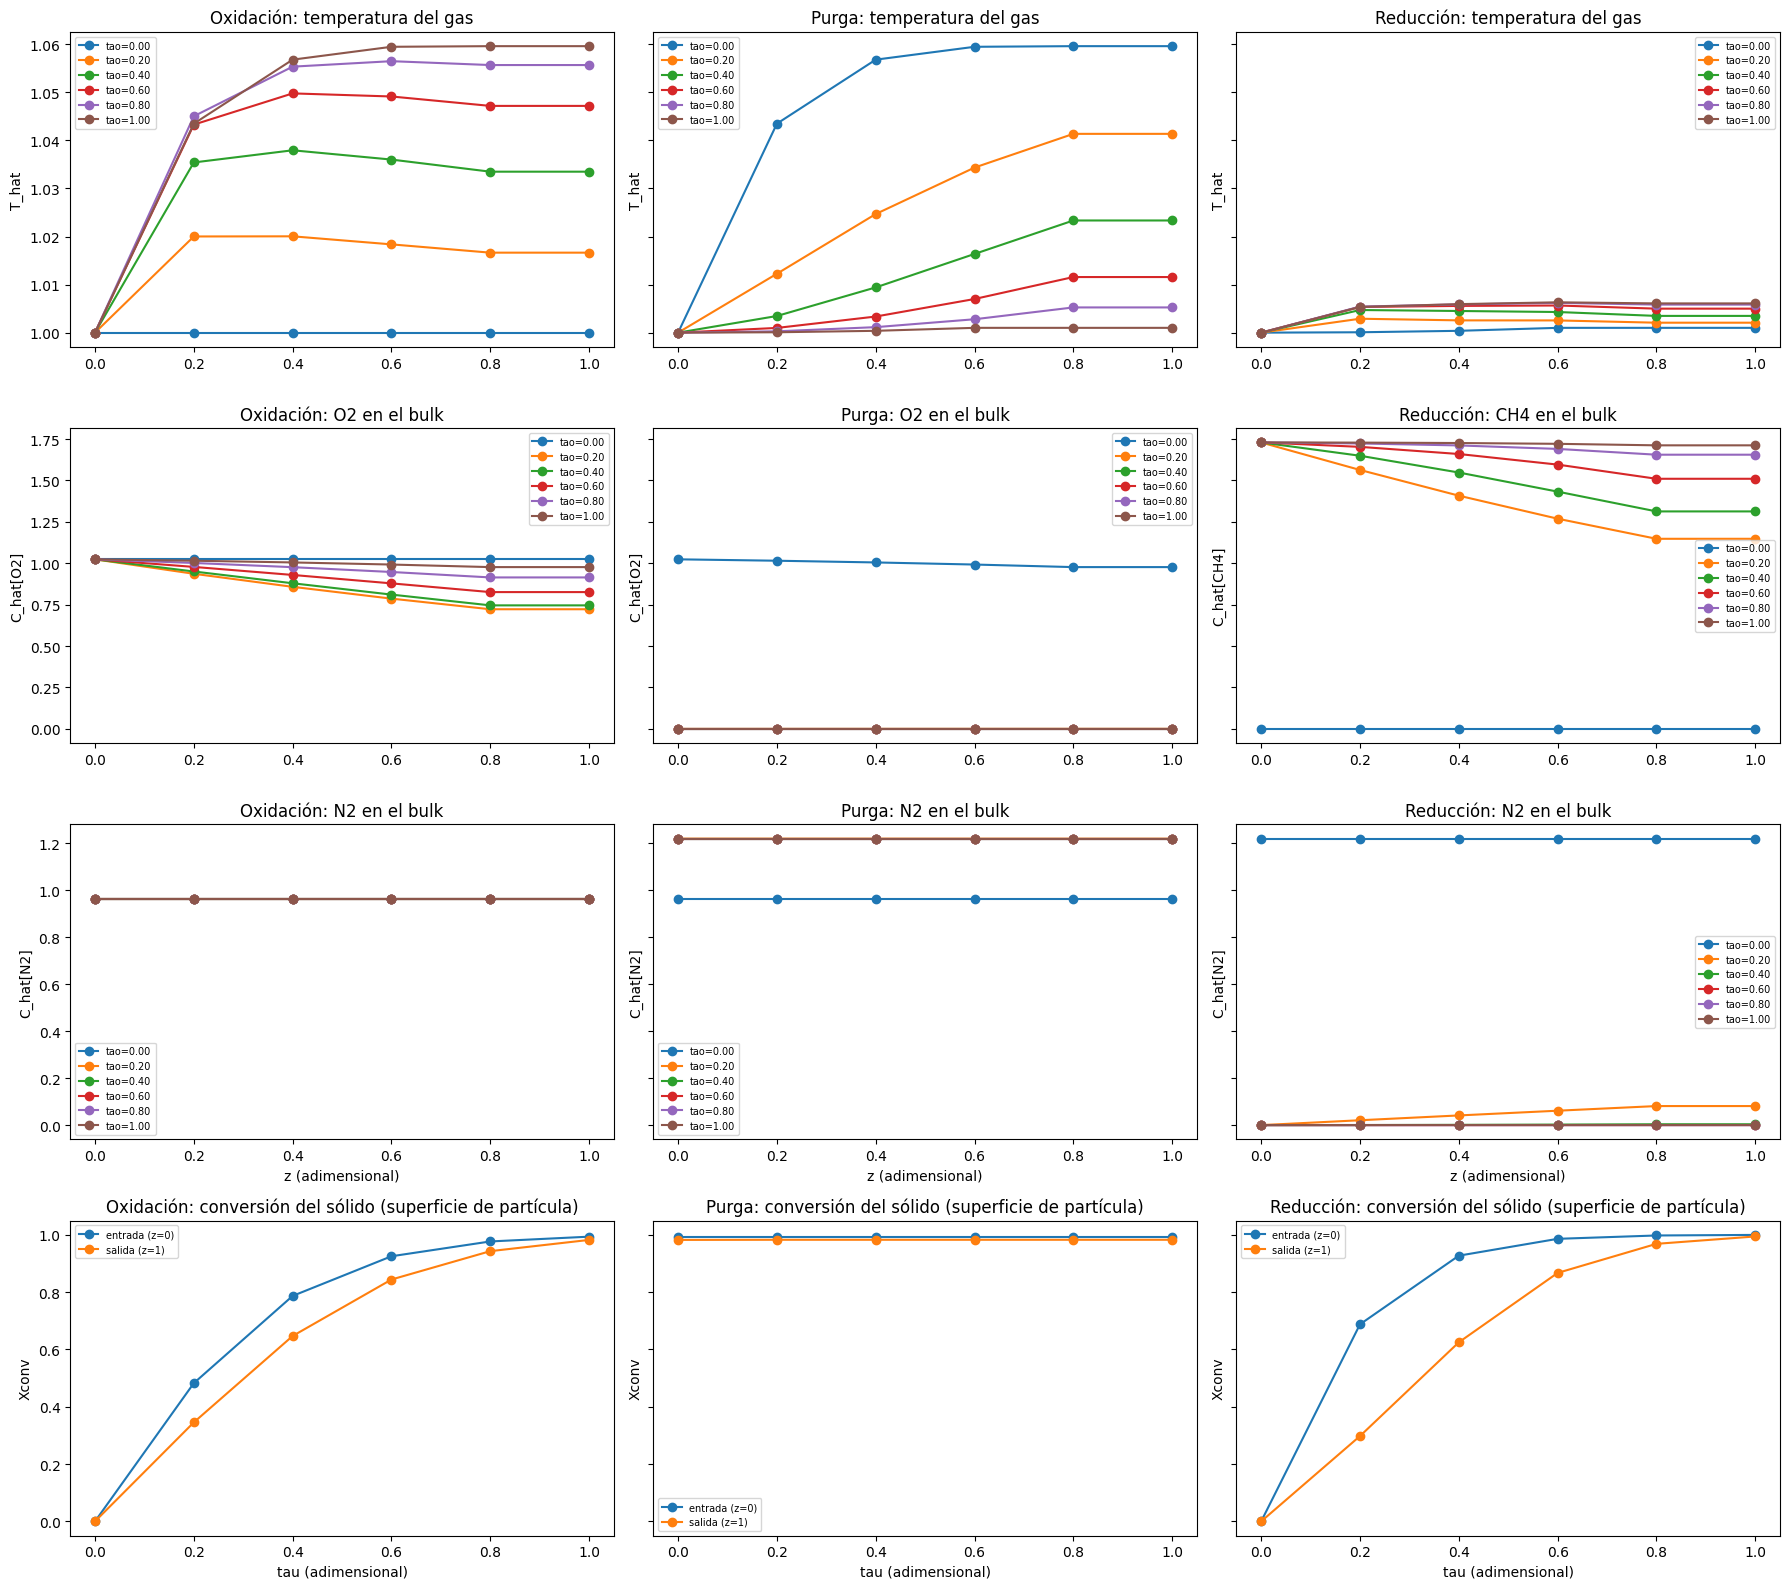

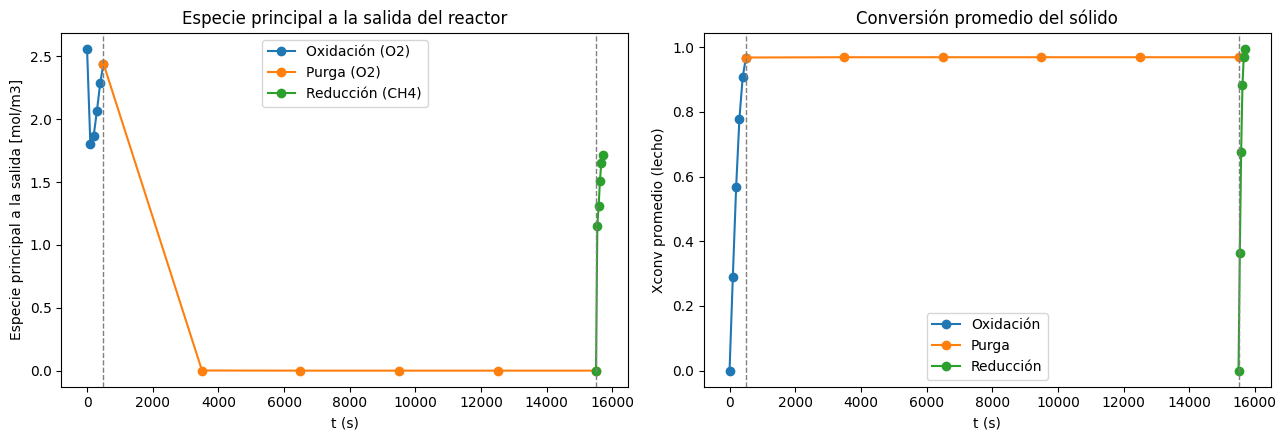

In [43]:
import matplotlib.pyplot as plt

etapas = [("Oxidación", modelo.ox, "O2"), ("Purga", modelo.purge, "O2"), ("Reducción", modelo.red, "CH4")]
zs = sorted(modelo.ox.A)        # asumiendo misma malla axial en las 3 etapas (nz igual)
rs = sorted(modelo.ox.R)

# ===== Perfiles por etapa: una columna por etapa, mismas escalas por fila para poder compararlas =====
fig, axs = plt.subplots(4, 3, figsize=(18, 16), sharex="row", sharey="row")
for j, (nombre, blk, sp_principal) in enumerate(etapas):
    taos = sorted(blk.T)

    # 1. Perfil de temperatura del gas (T_hat) vs z, para cada tao
    for tao in taos:
        axs[0, j].plot(zs, [pyo.value(blk.T_hat[z, tao]) for z in zs], marker='o', label=f'tao={tao:.2f}')
    axs[0, j].set_title(f'{nombre}: temperatura del gas')
    axs[0, j].set_ylabel('T_hat')

    # 2. Perfil de la especie principal de la etapa (O2 en ox/purga, CH4 en reduccion)
    for tao in taos:
        axs[1, j].plot(zs, [pyo.value(blk.C_hat[sp_principal, z, tao]) for z in zs], marker='o', label=f'tao={tao:.2f}')
    axs[1, j].set_title(f'{nombre}: {sp_principal} en el bulk')
    axs[1, j].set_ylabel(f'C_hat[{sp_principal}]')

    # 3. Perfil de concentración de N2 (comun a las 3 etapas)
    for tao in taos:
        axs[2, j].plot(zs, [pyo.value(blk.C_hat["N2", z, tao]) for z in zs], marker='o', label=f'tao={tao:.2f}')
    axs[2, j].set_title(f'{nombre}: N2 en el bulk')
    axs[2, j].set_ylabel('C_hat[N2]')
    axs[2, j].set_xlabel('z (adimensional)')

    # 4. Conversión del solido vs tiempo, en la superficie de la particula, entrada vs salida del reactor
    for etiqueta, z in [('entrada (z=0)', zs[0]), ('salida (z=1)', zs[-1])]:
        axs[3, j].plot(taos, [pyo.value(blk.Xconv[z, rs[-1], tao]) for tao in taos], marker='o', label=etiqueta)
    axs[3, j].set_title(f'{nombre}: conversión del sólido (superficie de partícula)')
    axs[3, j].set_ylabel('Xconv')
    axs[3, j].set_xlabel('tau (adimensional)')

for ax in axs.flat:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# ===== Continuidad entre etapas, en tiempo real: cada etapa arranca donde termina la anterior =====
tf_ox, tf_pu, tf_red = pyo.value(modelo.ox.tf), pyo.value(modelo.purge.tf), pyo.value(modelo.red.tf)
t_ox = [tao * tf_ox for tao in sorted(modelo.ox.T)]
t_pu = [tf_ox + tao * tf_pu for tao in sorted(modelo.purge.T)]
t_red = [tf_ox + tf_pu + tao * tf_red for tao in sorted(modelo.red.T)]

def salida(blk, sp):
    return [pyo.value(blk.C_hat[sp, zs[-1], tao]) * pyo.value(blk.Cnd_i[sp]) for tao in sorted(blk.T)]

def X_prom(blk):
    return [sum(pyo.value(blk.Xconv[z, r, tao]) for z in zs for r in rs)/(len(zs)*len(rs)) for tao in sorted(blk.T)]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(t_ox, salida(modelo.ox, "O2"), marker='o', label='Oxidación (O2)')
axs[0].plot(t_pu, salida(modelo.purge, "O2"), marker='o', label='Purga (O2)')
axs[0].plot(t_red, salida(modelo.red, "CH4"), marker='o', label='Reducción (CH4)')
axs[0].set_xlabel('t (s)'); axs[0].set_ylabel('Especie principal a la salida [mol/m3]'); axs[0].set_title('Especie principal a la salida del reactor')
axs[1].plot(t_ox, X_prom(modelo.ox), marker='o', label='Oxidación')
axs[1].plot(t_pu, X_prom(modelo.purge), marker='o', label='Purga')
axs[1].plot(t_red, X_prom(modelo.red), marker='o', label='Reducción')
axs[1].set_xlabel('t (s)'); axs[1].set_ylabel('Xconv promedio (lecho)'); axs[1].set_title('Conversión promedio del sólido')
for ax in axs:
    ax.axvline(tf_ox, color='gray', linestyle='--', linewidth=1)
    ax.axvline(tf_ox + tf_pu, color='gray', linestyle='--', linewidth=1)
    ax.legend()
plt.tight_layout()
plt.show()



In [ ]:
import h5py
from datetime import datetime

RUNS_DIR = r'C:\Users\srodr\OneDrive\Documentos\SRB\Waterloo\CLC - Chemical Looping Combustion\Code\RM CLC Optimization - Santiago\Runs'
os.makedirs(RUNS_DIR, exist_ok=True)


def exportar_etapa(archivo, nombre, blk, modelo, t_inicio=0.0, species_gas=None):
    """Escribe en el grupo /<nombre> del archivo h5 los resultados de una etapa (bloque blk).
    t queda en tiempo local de la etapa [s] (0 a tf); t_inicio es el instante de la etapa en el ciclo [s].
    species_gas: por defecto blk.I; para reduccion hay que pasar blk.GI (incluye CO2/H2O).

    X_Fe3O4 y X_Fe2O3: conversion de cada oxido (0 = nada convertido, 1 = totalmente convertido),
    referenciada a SU PROPIO punto de inicio natural en el ciclo completo -- Fe3O4 referenciado al
    inicio de la oxidacion (ahi esta "fresco", sin convertir), Fe2O3 referenciado al inicio de la
    reduccion (ahi esta "fresco", recien formado por la oxidacion). Con esa referencia fija (no la
    de cada bloque), las dos quedan genuinamente continuas en las 2 fronteras del ciclo (verificado
    numericamente: diferencia 0 en ambas) y van 0->1 en su etapa "de origen", igual que blk.Xconv.
    
    eng: Write the results of a stage (block blk) to the /<name> group of the h5 file. 
    
    The local time of the stage [s] (0 to tf);
         t_inicio is the stage's start time in the cycle [s].

    species_gas:
         by default blk.I; for reduction, use blk.GI (includes CO2/H2O).
    X_Fe3O4 and X_Fe2O3: 
        conversion of each oxide (0 = not converted, 1 = fully converted),

    referenced to ITS OWN natural starting point in the complete cycle -- Fe3O4 referenced to the
    start of oxidation (it is "fresh," unconverted), Fe2O3 referenced to the start of
    reduction (it is "fresh," newly formed by oxidation). 
    
    With that fixed reference (not the one of each block), the two remain genuinely continuous at the 2 boundaries of the cycle 
    (verified numerically: difference 0 in both) and go 0->1 in their "origin" stage, just like blk.Xconv.
    
    """
    zs, taos, rs = sorted(blk.A), sorted(blk.T), sorted(blk.R)
    species_gas = list(species_gas) if species_gas is not None else list(blk.I)
    species_solid, streams = list(blk.S), list(blk.F)

    L_val, Rp_val, tf_val = pyo.value(modelo.L), pyo.value(blk.Rp), pyo.value(blk.tf)
    Tnd_val, Ac_val = pyo.value(blk.Tnd), pyo.value(blk.Ac)

    z_dim = np.array(zs) * L_val
    r_dim = np.array(rs) * Rp_val
    t_dim = np.array(taos) * tf_val

    T_dim = np.array([[pyo.value(blk.T_hat[z, tao]) * Tnd_val for tao in taos] for z in zs])
    Tc_dim = np.array([[[pyo.value(blk.Tc_hat[z, r, tao]) * Tnd_val for tao in taos] for r in rs] for z in zs])

    tao0_ox, tao0_red = modelo.ox.T.first(), modelo.red.T.first()

    def frac(s, ref_blk, ref_tao0):
        Cref = {(z, r): pyo.value(ref_blk.Ccs_hat[s, z, r, ref_tao0]) for z in zs for r in rs}
        return np.array([[[1 - pyo.value(blk.Ccs_hat[s, z, r, tao]) / Cref[(z, r)] for tao in taos] for r in rs] for z in zs])

    X_Fe3O4_dim = frac("Fe3O4", modelo.ox, tao0_ox)
    X_Fe2O3_dim = frac("Fe2O3", modelo.red, tao0_red)

    m_stream = {s: np.array([pyo.value(blk.m[s, tao]) for tao in taos]) for s in streams}
    m_total = np.array([pyo.value(sum(blk.m[s, tao] for s in streams)) for tao in taos])
    y_in = {i: np.array([pyo.value(blk.y_feed[i, tao]) for tao in taos]) for i in species_gas}
    MW_in = sum(y_in[i] * pyo.value(blk.M_i[i]) for i in species_gas)
    w_in = {i: y_in[i] * pyo.value(blk.M_i[i]) / MW_in for i in species_gas}
    F_dim = {i: np.array([[pyo.value(blk.w[i, z, tao]) * pyo.value(blk.G[tao]) * Ac_val for tao in taos] for z in zs])
             for i in species_gas}

    g = archivo.create_group(nombre)
    g_ejes = g.create_group('parametros/ejes')
    g_ejes.create_dataset('z', data=z_dim)
    g_ejes.create_dataset('r', data=r_dim)
    g_ejes.create_dataset('t', data=t_dim)

    g_par = g['parametros']
    g_par.attrs['L'] = L_val
    g_par.attrs['Di'] = pyo.value(modelo.Di)
    g_par.attrs['tf'] = tf_val
    g_par.attrs['t_inicio'] = t_inicio
    g_par.attrs['species_gas'] = species_gas
    g_par.attrs['species_solid'] = species_solid
    g_par.attrs['streams'] = streams

    g_var = g.create_group('variables')
    g_var.create_dataset('T', data=T_dim)
    g_var.create_dataset('Tc', data=Tc_dim)
    g_var.create_dataset('X_Fe3O4', data=X_Fe3O4_dim)
    g_var.create_dataset('X_Fe2O3', data=X_Fe2O3_dim)
    g_var.create_dataset('m_total', data=m_total)
    for s in streams:
        g_var.create_dataset(f'm_{s}', data=m_stream[s])
    for i in species_gas:
        Cnd_i_val = pyo.value(blk.Cnd_i[i])
        g_var.create_dataset(f'C_{i}', data=np.array([[pyo.value(blk.C_hat[i, z, tao]) * Cnd_i_val for tao in taos] for z in zs]))
        g_var.create_dataset(f'Cci_{i}', data=np.array([[[pyo.value(blk.Cci_hat[i, z, r, tao]) * Cnd_i_val for tao in taos] for r in rs] for z in zs]))
        g_var.create_dataset(f'F_{i}', data=F_dim[i])
        g_var.create_dataset(f'y_in_{i}', data=y_in[i])
        g_var.create_dataset(f'w_in_{i}', data=w_in[i])
    for s in species_solid:
        Cnd_s_val = pyo.value(blk.Cnd_s[s])
        g_var.create_dataset(f'Ccs_{s}', data=np.array([[[pyo.value(blk.Ccs_hat[s, z, r, tao]) * Cnd_s_val for tao in taos] for r in rs] for z in zs]))


timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
fpath = os.path.join(RUNS_DIR, f'{timestamp} -- CLC_COMPLETE_CYCLE_results.h5')

tf_ox = pyo.value(modelo.ox.tf)
tf_pu = pyo.value(modelo.purge.tf)
dof_final = count_dof(modelo, verbose=False)

with h5py.File(fpath, 'w') as f:
    f.attrs['formato'] = 2
    f.attrs['etapas'] = ['ox', 'purge', 'red']
    f.attrs['solver_status'] = str(results1.solver.termination_condition)
    f.attrs['dof'] = dof_final
    f.attrs['tipo_corrida'] = 'simulacion' if dof_final == 0 else 'optimizacion'

    exportar_etapa(f, 'ox', modelo.ox, modelo, t_inicio=0.0)
    exportar_etapa(f, 'purge', modelo.purge, modelo, t_inicio=tf_ox)
    exportar_etapa(f, 'red', modelo.red, modelo, t_inicio=tf_ox + tf_pu, species_gas=list(modelo.red.GI))

    g_dec = f.create_group('decisiones')
    g_dec.attrs['L'] = pyo.value(modelo.L)
    g_dec.attrs['Di'] = pyo.value(modelo.Di)
    for nombre, blk in [('ox', modelo.ox), ('purge', modelo.purge)]:
        t0 = blk.T.first()
        g_dec.attrs[f'{nombre}_tf'] = pyo.value(blk.tf)
        g_dec.attrs[f'{nombre}_m_air'] = pyo.value(blk.m['Air', t0])
        g_dec.attrs[f'{nombre}_m_N2'] = pyo.value(blk.m['N2', t0])
    t0_r = modelo.red.T.first()
    g_dec.attrs['red_tf'] = pyo.value(modelo.red.tf)
    g_dec.attrs['red_m_CH4'] = pyo.value(modelo.red.m['CH4', t0_r])
    g_dec.attrs['red_m_CO'] = pyo.value(modelo.red.m['CO', t0_r])
    g_dec.attrs['red_m_H2'] = pyo.value(modelo.red.m['H2', t0_r])

    decision_vars = [("L", modelo.L), ("Di", modelo.Di),
                      ("ox_tf", modelo.ox.tf), ("purge_tf", modelo.purge.tf), ("red_tf", modelo.red.tf)]
    g_dec.create_dataset('decision_nombres', data=[n for n, v in decision_vars])
    g_dec.create_dataset('decision_libre', data=[not v.fixed for n, v in decision_vars])
    g_dec.create_dataset('decision_valor', data=[pyo.value(v) for n, v in decision_vars])

print(f"Resultados exportados a: {fpath}  (dof={dof_final}, {'simulacion' if dof_final==0 else 'optimizacion'})")


Resultados exportados a: C:\Users\srodr\OneDrive\Documentos\SRB\Waterloo\CLC - Chemical Looping Combustion\Code\RM CLC Optimization - Santiago\Runs\20261001_235331 -- CLC_COMPLETE_CYCLE_results.h5  (dof=2, optimizacion)


In [45]:
blk = modelo.ox
zs = sorted(blk.A)
taos = sorted(blk.T)

Tnd_val = pyo.value(blk.Tnd)
tf_val = pyo.value(blk.tf)
L_val = pyo.value(modelo.L)
D_val = pyo.value(modelo.Di)

print(f"L={L_val:.3f} m, D={D_val:.3f} m, tf={tf_val:.1f} s\n")

print("=== T [K], rho_g [kg/m3], vel [m/s]  (z, t real) ===")
for z in zs:
    for tao in taos:
        t_real = tao * tf_val
        T_K = pyo.value(blk.T_hat[z, tao]) * Tnd_val
        rho = pyo.value(blk.rho_g[z, tao])
        v = pyo.value(blk.vel[z, tao])
        print(f"z={z*L_val:.3f} m, t={t_real:6.1f} s  ->  T={T_K:8.2f} K   rho_g={rho:7.4f} kg/m3   vel={v:7.4f} m/s")

print("\n=== C[O2], C[N2] [mol/m3]  (z, t real) ===")
for z in zs:
    for tao in taos:
        t_real = tao * tf_val
        C_O2 = pyo.value(blk.C_hat['O2', z, tao]) * pyo.value(blk.Cnd_i['O2'])
        C_N2 = pyo.value(blk.C_hat['N2', z, tao]) * pyo.value(blk.Cnd_i['N2'])
        print(f"z={z*L_val:.3f} m, t={t_real:6.1f} s  ->  C[O2]={C_O2:7.4f}   C[N2]={C_N2:7.4f}  mol/m3")


L=4.746 m, D=2.373 m, tf=500.0 s

=== T [K], rho_g [kg/m3], vel [m/s]  (z, t real) ===
z=0.000 m, t=   0.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.000 m, t= 100.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.000 m, t= 200.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.000 m, t= 300.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.000 m, t= 400.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.000 m, t= 500.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.949 m, t=   0.0 s  ->  T= 1000.00 K   rho_g= 0.3515 kg/m3   vel= 1.9301 m/s
z=0.949 m, t= 100.0 s  ->  T= 1020.01 K   rho_g= 0.3439 kg/m3   vel= 1.9727 m/s
z=0.949 m, t= 200.0 s  ->  T= 1035.41 K   rho_g= 0.3389 kg/m3   vel= 2.0018 m/s
z=0.949 m, t= 300.0 s  ->  T= 1043.28 K   rho_g= 0.3365 kg/m3   vel= 2.0158 m/s
z=0.949 m, t= 400.0 s  ->  T= 1045.02 K   rho_g= 0.3362 kg/m3   vel= 2.0180 m/s
z=0.949 m, t= 500.0 s  ->  T= 104